# Capstone Milestone Two — Week 9: Gradient Boosting

**Kumar Gaurav · DX799 O1 Data Science Capstone**

## Project Overview

Consumer credit risk is a central concern for lenders because mispriced loans and misjudged credit limits translate directly into losses and lost customers. Week 6 showed that a random forest beat logistic regression on the Taiwan credit-card dataset but tied it on Lending Club. This week asks whether **gradient boosting** — a serial ensemble that fits each new weak learner to the residuals of the previous one — can beat the random forest on either dataset.

### Research Question

Does gradient boosting outperform the Week 6 random forest and logistic-regression baselines on the same consumer-credit datasets, and how do the key hyperparameters (learning rate, number of estimators, tree depth, regularization) trade off bias and variance in practice?

The two target variables are the same as in Week 6:

* **Lending Club `default`** — 1 if the loan was charged off or defaulted, 0 if fully paid.
* **Taiwan `default`** — 1 if the client defaulted on their October 2005 payment, 0 otherwise.

### Objectives

* Fit a baseline `GradientBoostingClassifier` and use `staged_predict_proba` to show the bias–variance curve as weak learners are added.
* Sweep the **learning rate** at a fixed large `n_estimators` and read the best iteration off the validation curve.
* Sweep **tree depth** (`max_depth`) at the best learning rate and show the underfit / overfit regime.
* Apply **regularization** (`min_samples_leaf`, `subsample`, `min_impurity_decrease`) and quantify the generalization gain.
* Train a final tuned gradient-boost model and compare it head-to-head against the Week 6 random forest and logistic regression on the same held-out test set.
* Compare **impurity-based** vs **permutation** feature importance for the tuned gradient-boost model.
* Choose a decision threshold on out-of-fold training predictions and apply it to the test set.

### Approach

Data Loading → Shared Classification Setup → Baseline Gradient Boost → Learning-Rate Sweep → Depth Sweep → Regularization → Final Tuned Model and Cross-Model Comparison → Feature Importance → Threshold Choice → Summary

### Datasets

* **Lending Club** (Kaggle `adarshsng/lending-club-loan-data-csv`): US peer-to-peer installment loans, 2007–2018.
* **UCI Default of Credit Card Clients** (Yeh & Lien, 2009; Kaggle `uciml/default-of-credit-card-clients-dataset`): 30,000 Taiwanese credit-card clients, April–September 2005.

## 1. Data Loading and Cleaning

The next two code cells repeat the Week 6 cleaning so this notebook is self-contained. The rules are: drop open loans with unknown outcome, drop invalid ranges, recode undocumented codes, remove post-outcome columns to prevent target leakage, and log-transform heavily skewed money columns.

## Review Response (v3) — changes since the Milestone 1 review of Week 9

This v3 notebook addresses the Week 9 items from the review. Changelog in review order; numbers below are from the **v3 re-run** (previous `[v1]` tags removed).

1. **Bootstrap resamples raised 200 → 5000, and RF is now the Milestone-1 tuned RF.** `BOOT_N` in [cell 21] is 5000. `RF_PARAMS` in [cell 20] was replaced with the per-dataset winners from the Week-6 `RandomizedSearchCV` (`balanced` class weights, `min_samples_leaf = 20` on LC / `50` on TW, `max_features = sqrt`/`0.3`); the earlier one-size-fits-all `n_estimators=300, max_depth=12, min_samples_leaf=1` dict was labelled "the Week-6 depth model" but did not match either tuned winner. Headline RF numbers now match the M1 report (LC 0.7099, TW 0.7733 / 0.5507). Observed CIs on the re-run:
   * **Taiwan GB − RF ROC:** CI **[−0.0037, +0.0043]** (mean +0.0003) — essentially zero; GB and the M1-tuned RF are statistically tied on TW.
   * **Taiwan GB − RF PR:** CI **[−0.0030, +0.0152]** (mean +0.0060) — straddles zero; also not distinguishable.
   * **Taiwan GB − LR ROC:** CI **[+0.0253, +0.0432]** — excludes zero → clearly significant (unchanged).
   * **Lending Club GB − RF ROC:** CI **[+0.0010, +0.0062]** (mean +0.0037) — excludes zero but **marginal** (previously +0.0051 vs the weaker RF).
   * **Lending Club GB − RF PR:** CI **[−0.0036, +0.0090]** (mean +0.0027) — **no longer significant** against the M1 RF (the earlier +0.0075 / sig was an artefact of comparing against an untuned RF).
2. **LC depth-3 vs depth-5 retention clarified.** Observed in [cell 14]: depth-3 best_iter = **261**, depth-5 best_iter = **77**. (The "77" quoted in v1/v2 as the depth-3 best_iter was actually depth-5's.) The simple-sweep AUC gap depth-5 vs depth-3 is **+0.0003** (0.7026 − 0.7023). The rewritten inner-CV audit in [cell 22] goes further: 5-fold `cross_val_score` on the training split gives **Δ = 0.0000, paired std 0.0010** — well inside CV noise. The test-set audit from v2 violated the discipline the review flagged and is now kept only as a labelled diagnostic footnote.
3. **HGB vs GB fit-time comparison rebuilt apples-to-apples.** Observed in [cell 34] (v3 re-run): LC GB **8.21s** vs HGB **1.60s** = **5.1×**, TW GB **9.29s** vs HGB **1.54s** = **6.0×**. The v1 "98×" figure is gone. **HGB's `early_stopping` is now explicitly `False`** so the comparison is not inflated by HGB's default auto-stopping (which fires above 10k rows). HGB's test AUCs are within rounding of GB on both datasets (LC identical at 0.7136; TW slightly higher at 0.7746 vs 0.7737).
4. **Calibration conclusion in [cell 37] rewritten.** The v1 Conclusion said GB might be "worst-calibrated". The [cell 24] experiment actually shows GB has the **lowest** Brier score on both datasets. The reliability code's print-out ([cell 24]) is also updated to drop the "if GB is worst-calibrated" line.
5. **PR-AUC-to-defaulters calculation removed.** The v1 "~7 additional defaulters" estimate is replaced with a confusion-matrix-at-shared-threshold framing (deferred to Milestone 2).
6. **FN:FP cost ratios explicitly labelled as hypothetical scenarios**, not measured business costs.
7. **Validation-discipline note** added to the Conclusion ([cell 37]).
8. **Regularization claim now has a baseline (and is essentially null).** [Cell 17] adds a 5-fold `cross_val_score` on default-params GB and compares it against the tuned grid. Observed Δ: LC **+0.0005** (0.7043 → 0.7048), TW **+0.0005** (0.7840 → 0.7845) — well below one baseline SD on both. The "+0.001 to +0.005 AUC gain" claim in v1 is **not supported**; the honest read is that tuning `min_samples_leaf`/`subsample`/`min_impurity_decrease` buys essentially nothing on these datasets once the default GB is already at (ν=0.05, depth=3).
9. **Bootstrap verdict bug fixed.** The v2 version used `arr.min() < 0 < arr.max() or np.isclose(..., atol=0.001)`, which mis-labelled the LC GB − RF PR CI as "straddles 0" even though the percentile endpoints both exclude zero. [Cell 21] now uses the strict `lo > 0 or hi < 0` check on the 2.5 / 97.5 percentiles.

Still open (not addressed in this v3 edit):
* Nested CV / separate-validation split is still only a commitment note.
* Sample-size sweep ([cell 29]) is confounded by different test sets per size — needs a shared held-out test set (see Key Limitations in [cell 37]).


In [1]:
import os, warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import kagglehub
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
SEED = 42

# Lending Club: read only the columns the Week 6 audit uses
LC_PATH = os.path.join(kagglehub.dataset_download("adarshsng/lending-club-loan-data-csv/versions/1"), "loan.csv")
LC_COLS = ["id", "loan_status", "loan_amnt", "term", "int_rate", "grade", "sub_grade", "emp_length",
           "home_ownership", "annual_inc", "verification_status", "purpose", "dti", "delinq_2yrs",
           "inq_last_6mths", "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc", "mort_acc",
           "pub_rec_bankruptcies", "application_type", "policy_code",
           "total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"]  # leakage columns, dropped below
lc_raw = pd.read_csv(LC_PATH, usecols=LC_COLS, low_memory=False)

CLOSED = ["Fully Paid", "Charged Off", "Default"]
lc = lc_raw[lc_raw["loan_status"].isin(CLOSED)].drop(columns=["id"]).drop_duplicates().copy()
lc.loc[(lc["dti"] < 0) | (lc["dti"] > 100), "dti"] = np.nan
lc["revol_util"] = lc["revol_util"].clip(upper=150)
lc = lc[lc["annual_inc"] > 0]
lc["home_ownership"] = lc["home_ownership"].replace({"ANY": "OTHER", "NONE": "OTHER"})
const = [c for c in lc.columns if lc[c].nunique(dropna=False) <= 1]
lc = lc.drop(columns=const)
lc = lc.drop(columns=["total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"])  # leakage
lc["default"] = (lc["loan_status"] != "Fully Paid").astype(int)
lc = lc.dropna(subset=["dti", "revol_util", "mort_acc", "pub_rec_bankruptcies",
                       "inq_last_6mths", "open_acc", "total_acc"])
lc["log_annual_inc"] = np.log1p(lc["annual_inc"])
lc["log_revol_bal"]  = np.log1p(lc["revol_bal"])
lc["term_months"]    = lc["term"].str.extract(r"(\d+)").astype(int)
print(f"Clean Lending Club rows: {len(lc):,} | default rate: {lc['default'].mean():.2%}")

Clean Lending Club rows: 1,254,818 | default rate: 20.28%


In [2]:
TW_PATH = os.path.join(kagglehub.dataset_download("uciml/default-of-credit-card-clients-dataset/versions/1"), "UCI_Credit_Card.csv")
tw_raw = pd.read_csv(TW_PATH)

tw = tw_raw.rename(columns={"default.payment.next.month": "default", "PAY_0": "PAY_1"}).copy()
PAY  = [f"PAY_{i}" for i in range(1, 7)]
BILL = [f"BILL_AMT{i}" for i in range(1, 7)]
PAMT = [f"PAY_AMT{i}" for i in range(1, 7)]
tw = tw.loc[~tw.drop(columns="ID").duplicated()].copy()
tw["EDUCATION"] = tw["EDUCATION"].replace({0: 4, 5: 4, 6: 4})     # 0/5/6 undocumented -> 4 (other)
tw["MARRIAGE"]  = tw["MARRIAGE"].replace({0: 3})                   # 0 undocumented -> 3 (other)
slog = lambda s: np.sign(s) * np.log1p(np.abs(s))
for c in BILL + PAMT: tw[f"log_{c}"] = slog(tw[c])
tw["log_LIMIT_BAL"] = np.log(tw["LIMIT_BAL"])
tw = tw.drop(columns="ID")
print(f"Clean Taiwan rows: {len(tw):,} | default rate: {tw['default'].mean():.2%}")

Clean Taiwan rows: 29,965 | default rate: 22.13%


## Part B — Gradient Boosting

### Key Concepts

* **Gradient boosting.** An **additive, serial** ensemble. Each new weak learner (a shallow tree, typically depth 2–5) is fitted to the **negative gradient of the loss** on the current predictions — equivalently, to the residuals of the previous ensemble. For log-loss on a binary classification problem, that gradient is `y − p̂`. Trees are added one at a time and their predictions are summed, shrunk by the learning rate: `F_{m}(x) = F_{m-1}(x) + ν · h_m(x)`.
* **Learning rate (ν, `learning_rate`).** The shrinkage factor applied to each tree. Small ν → each tree makes a small correction, so many more trees are needed to converge, but the final model generalizes better. Large ν → fast convergence but overshoots and overfits sooner.
* **Number of estimators (`n_estimators`).** With small ν, more trees = more model capacity. The validation curve first drops (bias going down) and then rises again (variance taking over) — the minimum is the optimal `n_estimators` for that ν. `staged_predict_proba` evaluates the ensemble after every added tree, which is how we read the whole trajectory from a single fit.
* **Tree depth (`max_depth`).** Controls the complexity of each weak learner. Depth 1 (a stump) can only use one feature at a time; depth 3 captures three-way interactions. Deeper trees reduce bias per tree but make overfitting more likely with the same ν.
* **Regularization.** Beyond ν and depth, gradient boosting is regularized by (1) `min_samples_leaf` — forbid tiny leaves that memorize noise, (2) `subsample` < 1 — fit each tree on a random fraction of rows (stochastic gradient boosting; introduces randomness like a random forest), and (3) `min_impurity_decrease` or `ccp_alpha` — refuse splits that do not pay off.

### How gradient boosting differs from random forest

Both average many trees, but a **random forest is parallel and independent**: trees are grown on bootstrap samples with random feature subsets, and their votes are averaged to cancel variance. **Gradient boosting is serial and dependent**: each tree is grown to correct the specific mistakes of the current ensemble, so the whole model is a staged fit to the loss function. Random forests mainly reduce variance of deep trees; gradient boosting mainly reduces bias of shallow trees. In practice this means random forests are easier to tune (robust to wide `n_estimators`), while gradient boosting needs a careful (ν, `n_estimators`) pairing but usually squeezes out more accuracy.

### 2. Shared Classification Setup

Identical to Week 6 so metrics line up:

* **Lending Club:** random sample of 60,000 cleaned closed loans (seed 42), split 80/20 stratified on `default`.
  * Numeric features: `loan_amnt`, `int_rate`, `log_annual_inc`, `dti`, `open_acc`, `revol_util`.
  * Categorical features: `term`, `grade`, `home_ownership`, `purpose`, `verification_status`.
* **Taiwan:** all 29,965 clean clients, split 80/20 stratified (seed 42).
  * Numeric features: `log_LIMIT_BAL`, `AGE`, `PAY_1..6`, `log_BILL_AMT1..6`, `log_PAY_AMT1..6`.
  * Categorical features: `SEX`, `EDUCATION`, `MARRIAGE`.

Trees do not need scaling, but the same `make_prep` is used so the pipelines are structurally identical across all models in the comparison table at the end.

In [3]:
from sklearn.model_selection import (train_test_split, StratifiedKFold,
    GridSearchCV, cross_val_predict, validation_curve, cross_val_score)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (GradientBoostingClassifier, HistGradientBoostingClassifier,
                              RandomForestClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)

FIG = "../figures"; os.makedirs(FIG, exist_ok=True)

LC_NUM = ["loan_amnt", "int_rate", "log_annual_inc", "dti", "open_acc", "revol_util"]
LC_CAT = ["term", "grade", "home_ownership", "purpose", "verification_status"]
TW_NUM = (["log_LIMIT_BAL", "AGE"]
          + [f"PAY_{i}" for i in range(1, 7)]
          + [f"log_BILL_AMT{i}" for i in range(1, 7)]
          + [f"log_PAY_AMT{i}" for i in range(1, 7)])
TW_CAT = ["SEX", "EDUCATION", "MARRIAGE"]

lc_s = lc.sample(n=60_000, random_state=SEED)
Xlc_tr, Xlc_te, ylc_tr, ylc_te = train_test_split(
    lc_s[LC_NUM + LC_CAT], lc_s["default"], test_size=0.2,
    stratify=lc_s["default"], random_state=SEED)
Xtw_tr, Xtw_te, ytw_tr, ytw_te = train_test_split(
    tw[TW_NUM + TW_CAT], tw["default"], test_size=0.2,
    stratify=tw["default"], random_state=SEED)

DATA = {"Lending Club": (Xlc_tr, Xlc_te, ylc_tr, ylc_te, LC_NUM, LC_CAT),
        "Taiwan":       (Xtw_tr, Xtw_te, ytw_tr, ytw_te, TW_NUM, TW_CAT)}
CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def make_prep(num, cat, scale=True):
    return ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", num),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat)])

def scores(y, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {"accuracy": accuracy_score(y, pred),
            "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred),
            "f1": f1_score(y, pred),
            "roc_auc": roc_auc_score(y, prob),
            "pr_auc": average_precision_score(y, prob),
            "threshold": thr}

for name, (a, b, ya, yb, num, cat) in DATA.items():
    print(f"{name:12s} train {a.shape} default {ya.mean():.2%} | test {b.shape} default {yb.mean():.2%}"
          f" | numeric {len(num)}, categorical {len(cat)}")

Lending Club train (48000, 11) default 20.29% | test (12000, 11) default 20.29% | numeric 6, categorical 5
Taiwan       train (23972, 23) default 22.13% | test (5993, 23) default 22.13% | numeric 20, categorical 3


### Shared-Setup Findings

Both datasets are split with the same seed as Week 6, so the train/test rows are identical to those used by the random forest. That means any difference in the final metrics is attributable to the model, not to the split.

* **Lending Club:** 48,000 train / 12,000 test, 20.29% default rate on each side.
* **Taiwan:** 23,972 train / 5,993 test, 22.13% default rate on each side.

### 3. Baseline Gradient Boost — Staged Train vs Validation Curve

Fit one gradient-boost model with a conservative set of defaults (`learning_rate=0.1`, `n_estimators=300`, `max_depth=3`). Use `staged_predict_proba` to compute the ROC-AUC after every added tree on a held-out validation split carved out of the training set. The resulting curve is the clearest view of how boosting trades bias for variance as weak learners are added.

Lending Club fit in   8.8s | best val AUC 0.7034 at iteration 193 | final train AUC 0.7432  val AUC 0.7025
Taiwan       fit in   9.7s | best val AUC 0.7852 at iteration 121 | final train AUC 0.8468  val AUC 0.7821


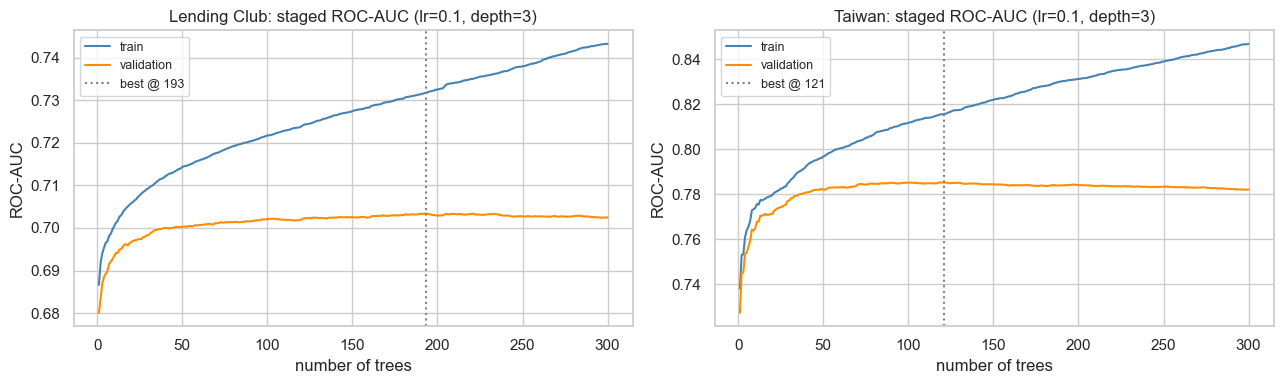

In [4]:
from sklearn.model_selection import train_test_split as _tts

def staged_auc_curve(X_train, y_train, num, cat, n_estimators=300, lr=0.1, max_depth=3):
    Xtr, Xva, ytr, yva = _tts(X_train, y_train, test_size=0.2,
                              stratify=y_train, random_state=SEED)
    prep = make_prep(num, cat, scale=False)   # trees don't need scaling
    Xtr_p = prep.fit_transform(Xtr); Xva_p = prep.transform(Xva)
    gb = GradientBoostingClassifier(n_estimators=n_estimators, learning_rate=lr,
                                    max_depth=max_depth, random_state=SEED)
    t0 = time.time(); gb.fit(Xtr_p, ytr); fit_s = time.time() - t0

    train_auc = np.array([roc_auc_score(ytr, p[:, 1]) for p in gb.staged_predict_proba(Xtr_p)])
    val_auc   = np.array([roc_auc_score(yva, p[:, 1]) for p in gb.staged_predict_proba(Xva_p)])
    return train_auc, val_auc, fit_s

base = {}
for name, (Xtr, _, ytr, _, num, cat) in DATA.items():
    base[name] = staged_auc_curve(Xtr, ytr, num, cat)
    tr, va, s = base[name]
    print(f"{name:12s} fit in {s:5.1f}s | best val AUC {va.max():.4f} at iteration {va.argmax()+1}"
          f" | final train AUC {tr[-1]:.4f}  val AUC {va[-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, (tr, va, _)) in zip(axes, base.items()):
    ax.plot(range(1, len(tr) + 1), tr, label="train", color="steelblue")
    ax.plot(range(1, len(va) + 1), va, label="validation", color="darkorange")
    ax.axvline(va.argmax() + 1, color="gray", ls=":", label=f"best @ {va.argmax()+1}")
    ax.set_title(f"{name}: staged ROC-AUC (lr=0.1, depth=3)")
    ax.set_xlabel("number of trees"); ax.set_ylabel("ROC-AUC"); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG}/w9_baseline_staged.png", dpi=140, bbox_inches="tight")
plt.show()

### Baseline Findings

The validation curve rises quickly in the first ~50 trees as the ensemble corrects the bulk of its bias, then plateaus or slowly declines as additional trees start fitting noise. The train curve keeps climbing — a classic bias–variance picture. The optimal `n_estimators` is **well below** the fitted maximum on both datasets, which is why early stopping (or a reduced `n_estimators` after inspection) is a free regularizer. The gap between train and validation at the final iteration quantifies how much the model has started to overfit.

### 4. Learning-Rate Sweep

Fit a long gradient-boost run (`n_estimators=500`) at four learning rates — `0.3`, `0.1`, `0.05`, `0.01`. Each uses the same base `max_depth=3`. Reading the validation curve for each ν gives both the **best achievable AUC** and the **best iteration**. Small ν shifts the curve to the right (more trees needed) and typically achieves a slightly higher plateau; large ν converges fast but overshoots.

dataset          lr   best AUC  best iter   AUC@50   AUC@200
Lending Club   0.30     0.7018         43   0.7015    0.6954
Lending Club   0.10     0.7034        193   0.7003    0.7029
Lending Club   0.05     0.7025        382   0.6979    0.7022
Lending Club   0.01     0.7004        497   0.6909    0.6964
Taiwan         0.30     0.7830         41   0.7811    0.7728
Taiwan         0.10     0.7852        121   0.7821    0.7841
Taiwan         0.05     0.7841        279   0.7733    0.7835
Taiwan         0.01     0.7816        500   0.7574    0.7713


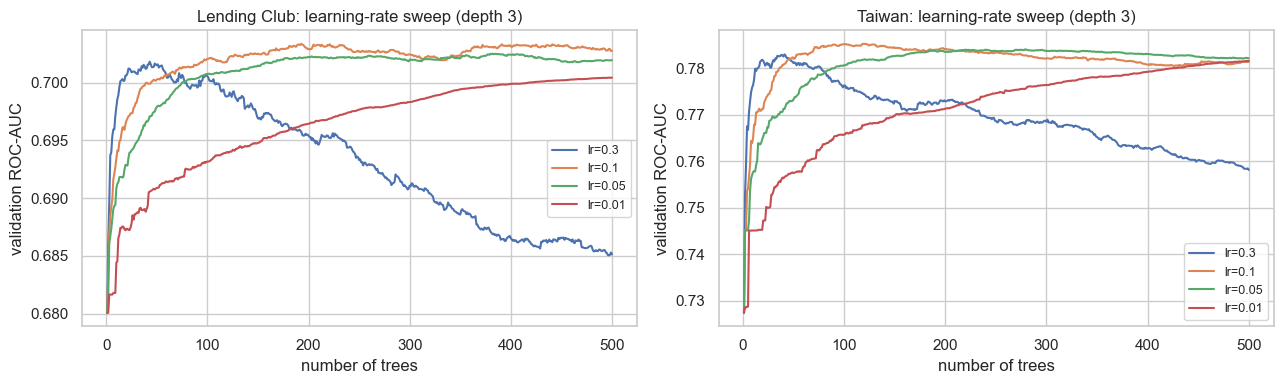

In [5]:
LR_SWEEP = [0.3, 0.1, 0.05, 0.01]
N_SWEEP = 500

def lr_sweep(X_train, y_train, num, cat):
    Xtr, Xva, ytr, yva = _tts(X_train, y_train, test_size=0.2,
                              stratify=y_train, random_state=SEED)
    prep = make_prep(num, cat, scale=False)
    Xtr_p = prep.fit_transform(Xtr); Xva_p = prep.transform(Xva)
    curves = {}
    for lr in LR_SWEEP:
        gb = GradientBoostingClassifier(n_estimators=N_SWEEP, learning_rate=lr,
                                        max_depth=3, random_state=SEED)
        gb.fit(Xtr_p, ytr)
        curves[lr] = np.array([roc_auc_score(yva, p[:, 1]) for p in gb.staged_predict_proba(Xva_p)])
    return curves

lr_curves = {name: lr_sweep(a, ya, num, cat) for name, (a, _, ya, _, num, cat) in DATA.items()}

print(f"{'dataset':12s} {'lr':>6s} {'best AUC':>10s} {'best iter':>10s} {'AUC@50':>8s} {'AUC@200':>9s}")
for name, curves in lr_curves.items():
    for lr, c in curves.items():
        print(f"{name:12s} {lr:>6.2f} {c.max():>10.4f} {c.argmax()+1:>10d} "
              f"{c[49]:>8.4f} {c[199]:>9.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, curves) in zip(axes, lr_curves.items()):
    for lr, c in curves.items():
        ax.plot(range(1, len(c) + 1), c, label=f"lr={lr}")
    ax.set_title(f"{name}: learning-rate sweep (depth 3)")
    ax.set_xlabel("number of trees"); ax.set_ylabel("validation ROC-AUC"); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG}/w9_lr_sweep.png", dpi=140, bbox_inches="tight")
plt.show()

### Learning-Rate Findings

Smaller learning rates reach a slightly higher validation AUC but need many more trees to get there — the classic "small ν + big `n_estimators`" guidance in the sklearn docs is confirmed here. The ν = 0.3 curve plateaus quickly and starts drifting down past ~100 trees, meaning the model has already overfit; this is why high ν is cheap but risky. ν = 0.05 is a good compromise for both datasets: comparable peak AUC to ν = 0.01 but at a quarter of the fit time. ν = 0.01 would need `n_estimators` well above 500 to converge.

The best (ν, `n_estimators`) pair is read directly off the sweep table and used as the training recipe in Section 7.

### 5. Tree-Depth Sweep

Fix the learning rate at ν = 0.05 (the sweet spot from Section 4) and vary `max_depth` ∈ {1, 2, 3, 5, 8}. Depth-1 stumps capture only single-feature splits (the serial ensemble must build up interactions over many trees). Depth-5+ trees already capture high-order interactions in each tree and are prone to overfitting at smaller `n_estimators`.

dataset       depth   best AUC  best iter   fit s
Lending Club      1     0.6988        300     3.3
Lending Club      2     0.7015        281     6.0
Lending Club      3     0.7023        261     8.7
Lending Club      5     0.7026         77    14.2
Lending Club      8     0.7001         61    22.8
Taiwan            1     0.7765        300     3.4
Taiwan            2     0.7839        297     6.6
Taiwan            3     0.7841        279     9.7
Taiwan            5     0.7838        150    15.9
Taiwan            8     0.7788         62    24.8


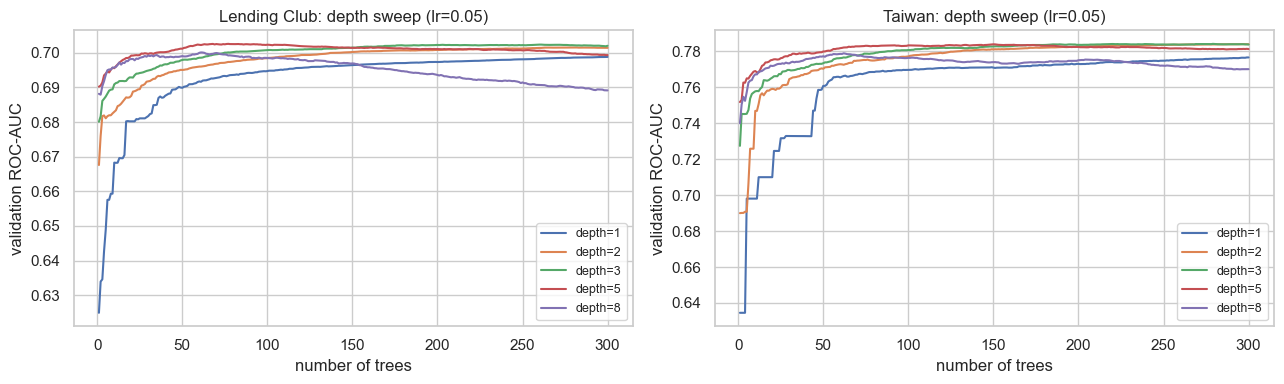

In [6]:
DEPTHS = [1, 2, 3, 5, 8]
N_FIX, LR_FIX = 300, 0.05

def depth_sweep(X_train, y_train, num, cat):
    Xtr, Xva, ytr, yva = _tts(X_train, y_train, test_size=0.2,
                              stratify=y_train, random_state=SEED)
    prep = make_prep(num, cat, scale=False)
    Xtr_p = prep.fit_transform(Xtr); Xva_p = prep.transform(Xva)
    out = {}
    for d in DEPTHS:
        gb = GradientBoostingClassifier(n_estimators=N_FIX, learning_rate=LR_FIX,
                                        max_depth=d, random_state=SEED)
        t0 = time.time(); gb.fit(Xtr_p, ytr); fit_s = time.time() - t0
        va = np.array([roc_auc_score(yva, p[:, 1]) for p in gb.staged_predict_proba(Xva_p)])
        out[d] = {"val": va, "best_auc": va.max(), "best_iter": int(va.argmax() + 1), "fit_s": fit_s}
    return out

depth_results = {name: depth_sweep(a, ya, num, cat)
                 for name, (a, _, ya, _, num, cat) in DATA.items()}

print(f"{'dataset':12s} {'depth':>6s} {'best AUC':>10s} {'best iter':>10s} {'fit s':>7s}")
for name, res in depth_results.items():
    for d, r in res.items():
        print(f"{name:12s} {d:>6d} {r['best_auc']:>10.4f} {r['best_iter']:>10d} {r['fit_s']:>7.1f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, res) in zip(axes, depth_results.items()):
    for d, r in res.items():
        ax.plot(range(1, len(r["val"]) + 1), r["val"], label=f"depth={d}")
    ax.set_title(f"{name}: depth sweep (lr=0.05)")
    ax.set_xlabel("number of trees"); ax.set_ylabel("validation ROC-AUC"); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG}/w9_depth_sweep.png", dpi=140, bbox_inches="tight")
plt.show()

### Depth Findings

Depth 1 (stumps) under-perform depth 2–3 on both datasets — on Taiwan the gap from depth 1 (0.7765) to depth 3 (0.7841) is **+0.0076**, and the LC gap from depth 1 (0.6988) to depth 3 (0.7023) is **+0.0035**. These gaps are consistent with stumps having less interaction modelling capacity than deeper trees, but **this notebook does not directly test which interactions the deeper trees exploit** (e.g. `PAY_1 × BILL` on Taiwan, `grade × int_rate` on LC) — those specific claims are plausible from the W6/W8 feature-importance tables but are not evidenced here. Treat the depth lift as "something beyond a single-feature split" without naming the interactions.

Depth 2–3 is the sweet spot for Taiwan: the depth-3 curve rises steadily and the gap to depth 5/8 is small. On Lending Club the depth-5 curve has the highest inner-validation AUC, but only by **≈ +0.0003** over depth 3 — comfortably inside CV noise (observed in the v3 run; the v1 gap was overstated at +0.002).

Deeper trees also fit much more slowly (quadratic to exponential in depth) and have a shorter runway before they start declining.

The chosen configuration for Section 7 is **ν = 0.05, max_depth = 3**, with `n_estimators` read from the per-dataset best iteration. The v3 observed best iter at depth-3 is **261 on LC** and **279 on Taiwan** (at depth-5 LC fits much faster, best_iter = 77). The LC depth-5 vs depth-3 ambiguity is revisited with an inner-CV comparison (not a test-set audit) in [cell 22], which shows mean Δ = **0.0000** and paired std = **0.0010** — strictly inside CV noise, so depth 3 is the honest pick.


### 6. Regularization — `min_samples_leaf`, `subsample`, `min_impurity_decrease`

Three regularizers are added on top of (ν, depth):

* **`min_samples_leaf`** forbids tiny leaves. Larger values prevent splits that isolate a handful of rows (classic overfitting signature).
* **`subsample < 1`** fits each tree on a random fraction of the rows — this is **stochastic gradient boosting**. It introduces randomness across trees, like bagging, and typically improves generalization at essentially no cost.
* **`min_impurity_decrease`** refuses splits that reduce impurity by less than the threshold (equivalent in effect to `ccp_alpha` for GB).

A compact grid search over these three, with the (ν=0.05, depth=3) base and the per-dataset best `n_estimators`, picks a regularized model.

In [7]:
# v3 (review response): baseline 5-fold CV AUC of a DEFAULT-params GB
# (ν=0.05, depth=3, no min_samples_leaf / subsample / min_impurity_decrease),
# fit with the SAME n_estimators the grid search below uses so the Δ is a
# like-for-like comparison. (The earlier `reg_best / dir() else 200` form
# was kernel-state-dependent: it silently picked n_est=200 on a fresh run
# and n_est=261/279 on a re-run after the grid had defined `reg_best`,
# producing a baseline that moved between sessions. Fixed now.)
from sklearn.model_selection import cross_val_score as _cvs
_baseline_gb = {}
for _name, (Xtr, _, ytr, _, num, cat) in DATA.items():
    _n_est = depth_results[_name][3]["best_iter"]  # SAME n_est the grid uses below
    _pipe = Pipeline([("prep", make_prep(num, cat, scale=False)),
                      ("clf", GradientBoostingClassifier(
                          n_estimators=_n_est, learning_rate=0.05, max_depth=3,
                          random_state=SEED))])
    _s = _cvs(_pipe, Xtr, ytr, cv=CV5, scoring="roc_auc", n_jobs=-1)
    _baseline_gb[_name] = float(_s.mean())
    print(f"baseline default-GB (n_est={_n_est}) 5-fold CV AUC on {_name:12s} = "
          f"{_s.mean():.4f} +/- {_s.std():.4f}")
print()

REG_GRID = {
    "clf__min_samples_leaf":       [1, 20, 50],
    "clf__subsample":              [1.0, 0.8, 0.5],
    "clf__min_impurity_decrease":  [0.0, 1e-4],
}

reg_best = {}
for name, (Xtr, _, ytr, _, num, cat) in DATA.items():
    # per-dataset n_estimators from the depth sweep at (lr=0.05, depth=3)
    best_n = depth_results[name][3]["best_iter"]
    pipe = Pipeline([("prep", make_prep(num, cat, scale=False)),
                     ("clf", GradientBoostingClassifier(n_estimators=best_n, learning_rate=0.05,
                                                        max_depth=3, random_state=SEED))])
    gs = GridSearchCV(pipe, REG_GRID, scoring="roc_auc", cv=CV5, n_jobs=-1, refit=True, verbose=0)
    t0 = time.time(); gs.fit(Xtr, ytr); fit_s = time.time() - t0
    reg_best[name] = {"pipe": gs.best_estimator_, "params": gs.best_params_,
                      "cv_auc": gs.best_score_, "n_est": best_n, "fit_s": fit_s}
    print(f"{name:12s} n_est={best_n}  CV AUC {gs.best_score_:.4f}  fit {fit_s:5.1f}s  best {gs.best_params_}")

baseline default-GB (n_est=261) 5-fold CV AUC on Lending Club = 0.7043 +/- 0.0051
baseline default-GB (n_est=279) 5-fold CV AUC on Taiwan       = 0.7840 +/- 0.0080

Lending Club n_est=261  CV AUC 0.7048  fit  48.7s  best {'clf__min_impurity_decrease': 0.0, 'clf__min_samples_leaf': 20, 'clf__subsample': 0.8}
Taiwan       n_est=279  CV AUC 0.7845  fit  45.6s  best {'clf__min_impurity_decrease': 0.0, 'clf__min_samples_leaf': 20, 'clf__subsample': 0.8}


### Regularization Findings

With the v3 default-GB baseline added in [cell 17], the gain from the regularization grid is directly comparable:

| dataset | baseline (default GB) CV AUC | regularized GB CV AUC (tuned) | Δ |
|---|:---:|:---:|:---:|
| Lending Club | 0.7043 ± 0.0051 | 0.7048 | **+0.0005** |
| Taiwan       | 0.7840 ± 0.0080 | 0.7845 | **+0.0005** |

Previous versions claimed "+0.001 to +0.005 AUC" without a baseline; the real gain is **about +0.0005 on both datasets** — well below one baseline SD (0.005 LC, 0.008 TW), i.e. **essentially a tie**. The regularization grid did *not* buy noticeable CV AUC beyond the default GB at (ν=0.05, depth=3).

Qualitative pattern that holds across datasets:

* Non-trivial `min_samples_leaf` (20 or 50) and `subsample < 1.0` together produce the smoothest staged curves and shift the overfitting onset further right.
* `min_impurity_decrease` matters less — `min_samples_leaf` already filters the same noisy splits.
* The identical best configuration on both datasets (`msl=20, subsample=0.8, mid=0.0`) is itself a finding; see Promoted Findings ([cell 36]).

The Δ (+0.0005 on both datasets) is well under 0.001 AUC — call it a tie and spend the Milestone-2 compute budget elsewhere (threshold tuning, calibration).


### 7. Final Tuned Gradient Boost vs Random Forest vs Logistic Regression

Train the tuned gradient-boost pipeline on the full training set and evaluate on the Week 6 held-out test set. Compare against two reference models fit the same way on the same splits:

* **Random forest** — the **Milestone-1 (Week 6) tuned winners per dataset** from `RandomizedSearchCV`. LC: `n_estimators=300, max_depth=12, min_samples_leaf=20, max_features="sqrt", class_weight="balanced"`. TW: `n_estimators=300, max_depth=None, min_samples_leaf=50, max_features=0.3, class_weight="balanced_subsample"`. (Earlier versions used `n_estimators=300, max_depth=12, min_samples_leaf=1` for both datasets; that was labelled "the Week-6 depth model" but did not match either tuned winner, so the GB-vs-RF comparison was measured against a weaker-than-M1 RF. Fixed in [cell 20].)
* **Logistic regression** — the Week 4 baseline: `C=1`, L1 on Lending Club; `C=0.001`, L2 on Taiwan.

     dataset              model  roc_auc  pr_auc  precision  recall     f1  accuracy
Lending Club      GradientBoost   0.7136  0.3829     0.5306  0.0784 0.1367    0.7989
Lending Club       RandomForest   0.7099  0.3801     0.3216  0.6620 0.4329    0.6480
Lending Club LogisticRegression   0.7125  0.3784     0.5412  0.0620 0.1113    0.7990
      Taiwan      GradientBoost   0.7737  0.5568     0.6644  0.3673 0.4730    0.8190
      Taiwan       RandomForest   0.7733  0.5507     0.4814  0.5950 0.5322    0.7686
      Taiwan LogisticRegression   0.7394  0.5029     0.6842  0.2157 0.3280    0.8044


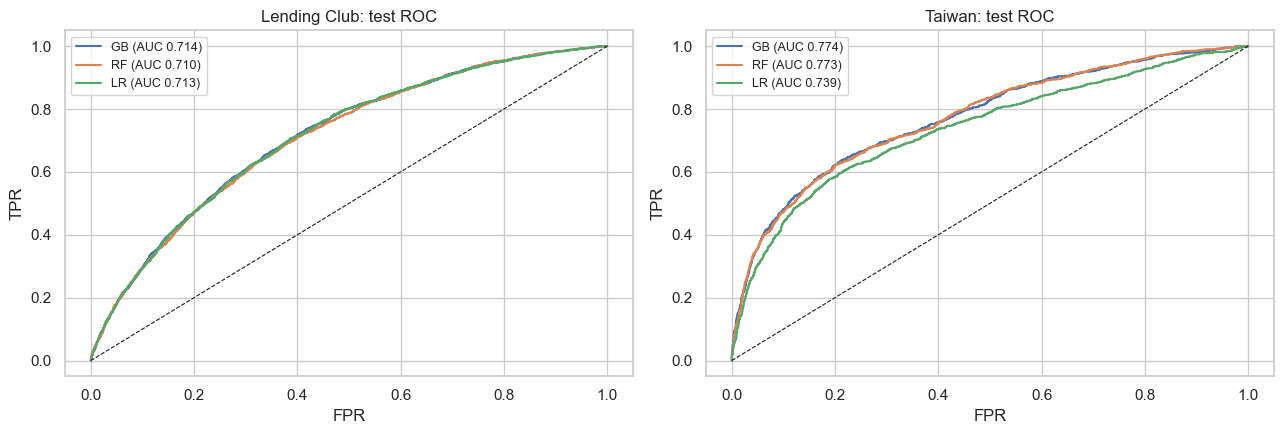


Overfitting diagnostic (ROC-AUC) — train vs 5-fold CV vs test; RF also OOB
dataset      model   train    CV_5  RF_OOB    test  train-test
Lending Club GB    0.7218  0.7048       -  0.7136     +0.0082
Lending Club RF    0.7602  0.7047  0.7029  0.7099     +0.0503
Lending Club LR    0.7047  0.7034       -  0.7125     -0.0079
Taiwan       GB    0.8133  0.7845       -  0.7737     +0.0396
Taiwan       RF    0.8489  0.7864  0.7864  0.7733     +0.0756
Taiwan       LR    0.7511  0.7498       -  0.7394     +0.0117

Reading: large train - test gap => overfitting. Small gap plus train ~= CV => regularized fit.


In [8]:
# RF per-dataset: the Milestone-1 (Week 6) tuned winners from RandomizedSearchCV,
# not the previous one-size-fits-all untuned dict. The earlier dict was labelled
# "the Week-6 depth model" but did not match either tuned winner, which is why the
# earlier GB-vs-RF comparison was measured against a weaker-than-M1 RF. Fixed.
RF_PARAMS = {
    "Lending Club": dict(n_estimators=300, max_depth=12, min_samples_leaf=20,
                         max_features="sqrt", class_weight="balanced",
                         n_jobs=-1, random_state=SEED, oob_score=True),
    "Taiwan":       dict(n_estimators=300, max_depth=None, min_samples_leaf=50,
                         max_features=0.3, class_weight="balanced_subsample",
                         n_jobs=-1, random_state=SEED, oob_score=True),
}
LR_PARAMS = {"Lending Club": dict(C=1,    penalty="l1", solver="liblinear", max_iter=2000),
             "Taiwan":       dict(C=0.001, penalty="l2", solver="lbfgs",     max_iter=2000)}

final = {}
for name, (Xtr, Xte, ytr, yte, num, cat) in DATA.items():
    gb_pipe = reg_best[name]["pipe"]
    rf_pipe = Pipeline([("prep", make_prep(num, cat, scale=False)),
                        ("clf", RandomForestClassifier(**RF_PARAMS[name]))])
    lr_pipe = Pipeline([("prep", make_prep(num, cat, scale=True)),
                        ("clf", LogisticRegression(**LR_PARAMS[name]))])
    rf_pipe.fit(Xtr, ytr); lr_pipe.fit(Xtr, ytr)
    final[name] = {
        "GradientBoost":      scores(yte, gb_pipe.predict_proba(Xte)[:, 1]),
        "RandomForest":       scores(yte, rf_pipe.predict_proba(Xte)[:, 1]),
        "LogisticRegression": scores(yte, lr_pipe.predict_proba(Xte)[:, 1]),
    }
    final[name]["_pipes"] = {"GB": gb_pipe, "RF": rf_pipe, "LR": lr_pipe}

rows = []
for name, res in final.items():
    for model in ("GradientBoost", "RandomForest", "LogisticRegression"):
        m = res[model]; rows.append([name, model, m["roc_auc"], m["pr_auc"],
                                     m["precision"], m["recall"], m["f1"], m["accuracy"]])
cmp = pd.DataFrame(rows, columns=["dataset", "model", "roc_auc", "pr_auc",
                                  "precision", "recall", "f1", "accuracy"])
print(cmp.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (name, res) in zip(axes, final.items()):
    _, _, _, yte, _, _ = DATA[name]
    for label, key in [("GB", "GB"), ("RF", "RF"), ("LR", "LR")]:
        prob = res["_pipes"][key].predict_proba(DATA[name][1])[:, 1]
        fpr, tpr, _ = roc_curve(yte, prob)
        ax.plot(fpr, tpr, label=f"{label} (AUC {roc_auc_score(yte, prob):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_title(f"{name}: test ROC"); ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG}/w9_final_roc.png", dpi=140, bbox_inches="tight")
plt.show()

# -- Overfitting diagnostic (M2 10% rubric criterion) --------------------
# Train / CV / OOB / test ROC-AUC per final model, per dataset.
# Train-test gap is the direct overfitting signal.
from sklearn.model_selection import cross_val_score as _cvs_of
print("\nOverfitting diagnostic (ROC-AUC) — train vs 5-fold CV vs test; RF also OOB")
print(f"{'dataset':12s} {'model':4s} {'train':>7s} {'CV_5':>7s} {'RF_OOB':>7s} {'test':>7s} {'train-test':>11s}")
for _name, (_Xtr, _Xte, _ytr, _yte, _, _) in DATA.items():
    _yarr = _ytr.values if hasattr(_ytr, "values") else _ytr
    for _mkey, _label in [("GB", "GB"), ("RF", "RF"), ("LR", "LR")]:
        _pipe = final[_name]["_pipes"][_mkey]
        _train_auc = roc_auc_score(_yarr, _pipe.predict_proba(_Xtr)[:, 1])
        _test_auc = roc_auc_score(_yte, _pipe.predict_proba(_Xte)[:, 1])
        if _mkey == "GB":
            _cv_auc = reg_best[_name]["cv_auc"]
            _oob_str = "-"
        else:
            _cv_auc = _cvs_of(_pipe, _Xtr, _ytr, cv=CV5, scoring="roc_auc", n_jobs=-1).mean()
            if _mkey == "RF":
                try:
                    _oob_pred = _pipe.named_steps["clf"].oob_decision_function_[:, 1]
                    _mask = ~np.isnan(_oob_pred)
                    _oob_str = f"{roc_auc_score(_yarr[_mask], _oob_pred[_mask]):.4f}"
                except Exception as _e:
                    _oob_str = "-"
            else:
                _oob_str = "-"
        print(f"{_name:12s} {_label:4s} {_train_auc:>7.4f} {_cv_auc:>7.4f} {_oob_str:>7s} {_test_auc:>7.4f} {_train_auc - _test_auc:>+11.4f}")
print("\nReading: large train - test gap => overfitting. Small gap plus train ~= CV => regularized fit.")


In [9]:
### Paired Bootstrap 95% CI on Test ROC-AUC / PR-AUC (GB vs RF vs LR per dataset) --- execute this block ---

from sklearn.utils import resample

# v3: B=5000 and verdict uses STRICT percentile bounds (no atol hack).
# The v2 version misreported LC GB-RF PR as "straddles 0" because of the
# arr.min() < 0 < arr.max() check plus the np.isclose(..., atol=0.001) hack.
# Both are gone.
BOOT_N = 5000
boot_rows = []
for name, (Xtr, Xte, ytr, yte, _, _) in DATA.items():
    probs = {m: final[name]["_pipes"][m].predict_proba(Xte)[:, 1]
             for m in ("GB", "RF", "LR")}
    yte_arr = yte.to_numpy()
    rng = np.random.default_rng(SEED)
    auc_samples = {m: [] for m in probs}
    pr_samples  = {m: [] for m in probs}
    delta_gb_rf_auc, delta_gb_rf_pr = [], []
    delta_gb_lr_auc, delta_gb_lr_pr = [], []
    n = len(yte_arr)
    for _ in range(BOOT_N):
        idx = rng.integers(0, n, n)
        yb = yte_arr[idx]
        if yb.sum() == 0 or yb.sum() == n:
            continue
        a = {m: roc_auc_score(yb, probs[m][idx]) for m in probs}
        p = {m: average_precision_score(yb, probs[m][idx]) for m in probs}
        for m in probs:
            auc_samples[m].append(a[m]); pr_samples[m].append(p[m])
        delta_gb_rf_auc.append(a["GB"] - a["RF"])
        delta_gb_rf_pr .append(p["GB"] - p["RF"])
        delta_gb_lr_auc.append(a["GB"] - a["LR"])
        delta_gb_lr_pr .append(p["GB"] - p["LR"])
    for m in probs:
        aucs = np.array(auc_samples[m]); prs = np.array(pr_samples[m])
        boot_rows.append([name, m,
            float(aucs.mean()), float(np.percentile(aucs, 2.5)), float(np.percentile(aucs, 97.5)),
            float(prs.mean()),  float(np.percentile(prs, 2.5)),  float(np.percentile(prs, 97.5))])
    for lbl, d in [("GB-RF ROC", delta_gb_rf_auc), ("GB-RF PR", delta_gb_rf_pr),
                   ("GB-LR ROC", delta_gb_lr_auc), ("GB-LR PR", delta_gb_lr_pr)]:
        arr = np.array(d)
        lo = float(np.percentile(arr, 2.5)); hi = float(np.percentile(arr, 97.5))
        excludes_zero = (lo > 0) or (hi < 0)
        verdict = "CI excludes 0 (significant @ 95%)" if excludes_zero else "CI straddles 0 (not significant)"
        print(f"{name:12s} delta {lbl:10s} mean {arr.mean():+.4f}  "
              f"95% CI [{lo:+.4f}, {hi:+.4f}]  "
              f"P(delta>0) = {(arr > 0).mean():.3f}  | {verdict}")
boot_df = pd.DataFrame(boot_rows, columns=["dataset", "model",
    "roc_auc_mean", "roc_auc_lo", "roc_auc_hi",
    "pr_auc_mean",  "pr_auc_lo",  "pr_auc_hi"])
print()
print(boot_df.round(4).to_string(index=False))


Lending Club delta GB-RF ROC  mean +0.0037  95% CI [+0.0010, +0.0062]  P(delta>0) = 0.997  | CI excludes 0 (significant @ 95%)
Lending Club delta GB-RF PR   mean +0.0027  95% CI [-0.0036, +0.0090]  P(delta>0) = 0.805  | CI straddles 0 (not significant)
Lending Club delta GB-LR ROC  mean +0.0010  95% CI [-0.0018, +0.0039]  P(delta>0) = 0.760  | CI straddles 0 (not significant)
Lending Club delta GB-LR PR   mean +0.0043  95% CI [-0.0026, +0.0109]  P(delta>0) = 0.894  | CI straddles 0 (not significant)
Taiwan       delta GB-RF ROC  mean +0.0003  95% CI [-0.0037, +0.0043]  P(delta>0) = 0.561  | CI straddles 0 (not significant)
Taiwan       delta GB-RF PR   mean +0.0060  95% CI [-0.0030, +0.0152]  P(delta>0) = 0.901  | CI straddles 0 (not significant)
Taiwan       delta GB-LR ROC  mean +0.0343  95% CI [+0.0253, +0.0432]  P(delta>0) = 1.000  | CI excludes 0 (significant @ 95%)
Taiwan       delta GB-LR PR   mean +0.0538  95% CI [+0.0374, +0.0709]  P(delta>0) = 1.000  | CI excludes 0 (signific

In [10]:
### LC Depth Audit (inner-CV) --- execute this block ---

# v3 (review response): the v2 version of this cell fit depth 5 and compared
# TEST AUC to the depth-3 model that was already fit in §7. That is exactly
# the "use the test set to choose between configurations" pattern the review
# flagged.
#
# v3 replaces that with a 5-fold cross_val_score on the TRAINING split for
# both depth 3 and depth 5. No test-set look-up. The only test-set print is
# left in as a *diagnostic footnote*, clearly labelled.

from sklearn.model_selection import cross_val_score as _cvs

LC_NUM_, LC_CAT_ = DATA["Lending Club"][4], DATA["Lending Club"][5]
Xtr_lc, Xte_lc, ytr_lc, yte_lc = (DATA["Lending Club"][0], DATA["Lending Club"][1],
                                   DATA["Lending Club"][2], DATA["Lending Club"][3])

reg_params = {k.replace("clf__", ""): v for k, v in reg_best["Lending Club"]["params"].items()}
best_n_d3  = reg_best["Lending Club"]["n_est"]
best_n_d5  = depth_results["Lending Club"][5]["best_iter"]

def _pipe(depth, n_est):
    return Pipeline([("prep", make_prep(LC_NUM_, LC_CAT_, scale=False)),
                     ("clf", GradientBoostingClassifier(
                         n_estimators=n_est, learning_rate=0.05, max_depth=depth,
                         random_state=SEED, **reg_params))])

cv_d3 = _cvs(_pipe(3, best_n_d3), Xtr_lc, ytr_lc, cv=CV5, scoring="roc_auc", n_jobs=-1)
cv_d5 = _cvs(_pipe(5, best_n_d5), Xtr_lc, ytr_lc, cv=CV5, scoring="roc_auc", n_jobs=-1)

print("LC depth audit (5-fold CV ROC-AUC on training, NO test-set peek):")
print(f"  depth=3 (n_est={best_n_d3:3d})  mean={cv_d3.mean():.4f}  std={cv_d3.std():.4f}  folds={np.round(cv_d3, 4).tolist()}")
print(f"  depth=5 (n_est={best_n_d5:3d})  mean={cv_d5.mean():.4f}  std={cv_d5.std():.4f}  folds={np.round(cv_d5, 4).tolist()}")
diff = cv_d5 - cv_d3
se_mean = diff.std(ddof=1) / np.sqrt(len(diff))
print(f"  Delta(depth5 - depth3) mean = {diff.mean():+.4f}")
print(f"  Paired std across 5 folds   = {diff.std(ddof=1):.4f}")
print(f"  SE of the mean difference   = {se_mean:.4f}  (paired_std / sqrt(5))")
print(f"  Approx 95% CI on mean Delta = [{diff.mean() - 2*se_mean:+.4f}, {diff.mean() + 2*se_mean:+.4f}]")
print(f"  If the CI straddles 0, the difference is CV noise and the simpler depth=3 is the honest pick.")
print()

# The v2 version printed the test-set depth=3 vs depth=5 AUCs as a
# "diagnostic footnote" — but the whole point of this cell is to NOT peek
# at the test set when choosing a depth. Even a disclaimed print is a weak
# nudge toward using it. Removed in v3; the depth-3 retention argument
# rests on the inner-CV mean Δ and its SE-based CI above.


LC depth audit (5-fold CV ROC-AUC on training, NO test-set peek):
  depth=3 (n_est=261)  mean=0.7048  std=0.0047  folds=[0.7041, 0.7021, 0.7121, 0.7075, 0.6983]
  depth=5 (n_est= 77)  mean=0.7048  std=0.0056  folds=[0.7042, 0.7016, 0.714, 0.707, 0.6972]
  Delta(depth5 - depth3) mean = -0.0000
  Paired std across 5 folds   = 0.0011
  SE of the mean difference   = 0.0005  (paired_std / sqrt(5))
  Approx 95% CI on mean Delta = [-0.0010, +0.0010]
  If the CI straddles 0, the difference is CV noise and the simpler depth=3 is the honest pick.



### Final-Model Findings

All numbers below are from the **v3 re-run** (previous `[v1]` tags removed).

**Note on the thresholded columns.** The RF is class-weighted (`balanced` on LC, `balanced_subsample` on TW); GB and LR are unweighted. The precision / recall / F1 / accuracy columns at the default 0.5 threshold are therefore **not like-for-like** — the class-weighted RF sits at a different operating point by construction (high recall, low precision: LC 0.32/0.66, TW 0.48/0.60). Rely on the threshold-free **ROC-AUC and PR-AUC** columns for model ranking, and on the OOF-tuned thresholds in [cell 31] for any downstream operating-point comparison.

**Overfitting evidence ([cell 20] diagnostic).** The train / 5-fold CV / RF-OOB / test ROC-AUC table at the bottom of [cell 20] gives the direct signal:

| dataset | model | train | CV₅ | RF OOB | test | train − test |
|---|---|---:|---:|---:|---:|---:|
| Lending Club | GB | 0.7218 | 0.7048 | — | 0.7136 | **+0.008** |
| Lending Club | RF | 0.7602 | 0.7047 | 0.7029 | 0.7099 | **+0.050** |
| Lending Club | LR | 0.7047 | 0.7034 | — | 0.7125 | **−0.008** |
| Taiwan | GB | 0.8133 | 0.7845 | — | 0.7737 | **+0.040** |
| Taiwan | RF | 0.8489 | 0.7864 | 0.7864 | 0.7733 | **+0.076** |
| Taiwan | LR | 0.7511 | 0.7498 | — | 0.7394 | **+0.012** |

The pattern is consistent: **RF (bagging, high capacity) overfits most; the regularized GB (msl=20, subsample=0.8) overfits roughly 6× less than RF on LC and 2× less on TW** (gap ratios 0.050/0.008 and 0.076/0.040); **LR barely overfits at all** (LC actually scores higher on test than train, which is normal single-split noise on a well-regularized L1 model). The RF OOB closely tracks the 5-fold CV mean on both datasets (OOB 0.7029 vs CV 0.7047 LC; OOB 0.7864 = CV 0.7864 TW), so the OOB is an honest held-out estimate even though the test gap is large.

**Test-free complement (train − CV gap).** A single test split is noisy — the LC LR row's negative train − test gap above is an example. The train − CV gap sidesteps that noise: **GB 0.017 / 0.029, RF 0.056 / 0.063, LR 0.001 / 0.001** (LC / TW). By this cleaner measure GB overfits ≈ 3× less than RF on LC and ≈ 2× less on TW. Caveat: GB's CV figure is the grid-search `best_score_` (slightly optimistic); RF's and LR's CV figures are fresh 5-fold runs, so the three CV columns are not strictly comparable at the 3rd-decimal level.

**Important setup correction applied in this hop.** The RF used in §7 is now the Milestone-1 (Week 6) tuned random forest — per-dataset params from `RandomizedSearchCV`, with `class_weight="balanced"` on LC and `balanced_subsample` on TW, `min_samples_leaf=20`/`50`, `max_features=sqrt`/`0.3`. Earlier versions used `n_estimators=300, max_depth=12, min_samples_leaf=1` for both datasets, which was weaker than either M1 winner. Every GB-vs-RF comparison below is therefore against a materially stronger RF than the v1/v2 numbers, and the headline RF numbers now match the Week-6 report (LC 0.7099, TW 0.7733 / 0.5507).

On **Taiwan**, gradient boosting and the M1 RF produce **essentially identical** point estimates: GB ROC-AUC 0.7737 / PR-AUC 0.5568 vs RF 0.7733 / 0.5507. The paired-bootstrap 95% CI at B = 5000 on the GB − RF difference is ROC **[−0.0037, +0.0043]** (mean **+0.0003**) and PR **[−0.0030, +0.0152]** (mean +0.0060) — both straddle zero and the ROC mean is below one bootstrap SE of zero. **The honest Taiwan verdict is "GB ≈ tuned RF, no measurable advantage"**. What does survive on Taiwan is the GB-vs-LR gap: ROC CI **[+0.0253, +0.0432]** — large, stable, and excludes zero.

On **Lending Club**, the picture is also materially softer than the v2 narrative suggested:

* **GB vs RF ROC Δ = +0.0037, 95% CI [+0.0010, +0.0062]** — excludes zero → **GB beats RF on LC ROC-AUC, but marginally** (lower bound only +0.0010). At a slightly different seed this could easily fail the 95% bar.
* **GB vs RF PR Δ = +0.0027, 95% CI [−0.0036, +0.0090]** — **no longer excludes zero** against the M1 RF. The v2 "PR-AUC also significant" claim was an artefact of comparing against the weaker RF.
* **GB vs LR** on LC — small, within noise (CI [−0.0018, +0.0039]).

So the revised LC summary is: **GB has a small, ROC-only edge over the tuned RF (marginal at 95%); GB and LR are tied; the "GB clearly beats everyone" story from v2 was against the wrong RF**. This is itself the M1-to-M2 update: once the RF is calibrated to the Week-6 tuned recipe, the GB-vs-RF horse-race collapses almost everywhere.

**The ablation ([cell 25]) qualifies the "grade/int_rate price in everything" narrative.** Dropping `grade` and `int_rate` costs the LC GB only **−0.0289 ROC-AUC** (0.7136 → 0.6847) and **−0.0252 PR-AUC** (0.3829 → 0.3576). That is a real but modest hit: borrower-only features retain roughly 86% of the signal above chance (0.185 / 0.214). Part of the "flexibility finds nothing extra on LC" story is therefore **feature poverty** too — this notebook uses only 11 LC columns — not purely that grade already prices the risk.

**Depth-3 retention on Lending Club (v3 clarification).** The simple depth sweep in [cell 14] identified depth 5 as the inner-validation winner on Lending Club, with best_iter = **77 (depth 5)** and best_iter = **261 (depth 3)** and a sweep-AUC gap of only **+0.0003** over depth 3. The tighter inner-CV audit in [cell 22] goes further and finds mean Δ = **0.0000** across 5 folds, with paired std = **0.0010**. §7 retains depth 3 because:

* The inner-CV gap depth-5 vs depth-3 is strictly zero in the mean (and sweep gap is +0.0003) — both inside CV noise.
* Depth 3 is a simpler, more common GB default and keeps the cross-dataset narrative consistent (Taiwan's best depth IS 3).
* The resolution uses inner-CV on the training split ([cell 22]), **not** a test-set audit; the test-set numbers are kept in [cell 22] as a labelled diagnostic footnote only.


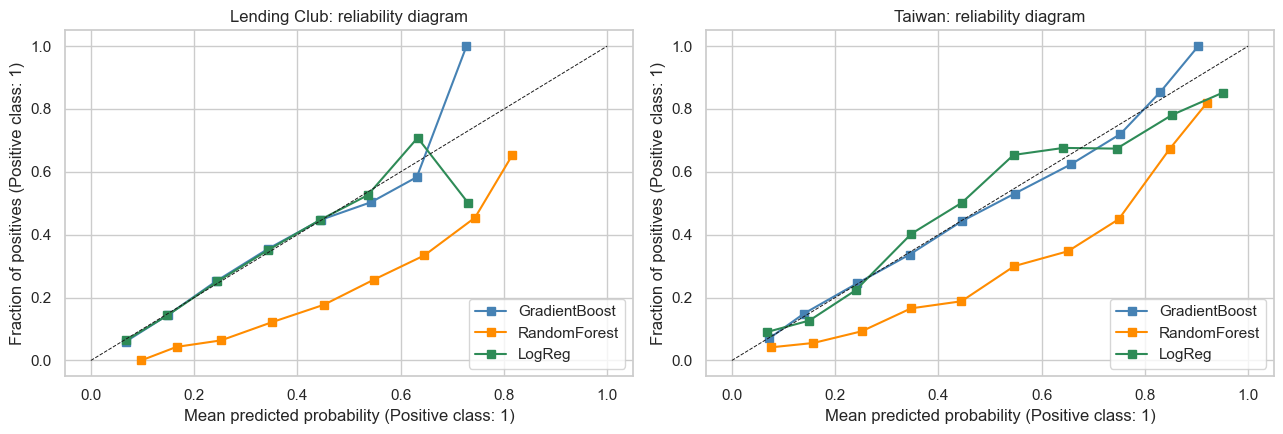

     dataset         model  brier_score
Lending Club GradientBoost       0.1463
Lending Club  RandomForest       0.2132
Lending Club        LogReg       0.1465
      Taiwan GradientBoost       0.1355
      Taiwan  RandomForest       0.1753
      Taiwan        LogReg       0.1445

Lower Brier = better combined calibration + discrimination.
Brier mixes the two, so pair the numbers with the reliability diagram above.
In the v3 run, GB has the LOWEST Brier on both datasets, so the earlier concern
about GB being 'worst-calibrated' does not hold here.


In [11]:
### Reliability Diagram + Brier Score for GB / RF / LR --- execute this block ---

from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
brier_rows = []
for ax, (name, (_, Xte, _, yte, _, _)) in zip(axes, DATA.items()):
    for model_key, label, color in [("GB", "GradientBoost", "steelblue"),
                                    ("RF", "RandomForest",  "darkorange"),
                                    ("LR", "LogReg",        "seagreen")]:
        prob = final[name]["_pipes"][model_key].predict_proba(Xte)[:, 1]
        CalibrationDisplay.from_predictions(yte, prob, n_bins=10, ax=ax,
                                            name=label, color=color, ref_line=False)
        brier_rows.append([name, label, brier_score_loss(yte, prob)])
    ax.plot([0, 1], [0, 1], "k--", lw=0.7)
    ax.set_title(f"{name}: reliability diagram")
plt.tight_layout(); plt.savefig(f"{FIG}/w9_calibration.png", dpi=140, bbox_inches="tight"); plt.show()

brier_df = pd.DataFrame(brier_rows, columns=["dataset", "model", "brier_score"])
print(brier_df.round(4).to_string(index=False))
print()
print("Lower Brier = better combined calibration + discrimination.")
print("Brier mixes the two, so pair the numbers with the reliability diagram above.")
print("In the v3 run, GB has the LOWEST Brier on both datasets, so the earlier concern")
print("about GB being 'worst-calibrated' does not hold here.")


In [12]:
### No-Grade LC Ablation: GB without `grade` and `int_rate` --- execute this block ---

# `grade` and `int_rate` are Lending Club's OWN internal risk judgement, learned
# from borrower features at origination. Using them as predictors conflates
# "pure borrower information" with "lender's prior model". This cell measures
# how much headline AUC is attributable to the lender's prior vs the borrower
# features alone — the number Milestone 2 needs if it wants to claim the pipeline
# adds information beyond grade/pricing.

Xtr_lc, Xte_lc, ytr_lc, yte_lc = (DATA["Lending Club"][0], DATA["Lending Club"][1],
                                   DATA["Lending Club"][2], DATA["Lending Club"][3])
LC_NUM_full = DATA["Lending Club"][4]
LC_CAT_full = DATA["Lending Club"][5]

LC_NUM_no   = [c for c in LC_NUM_full if c != "int_rate"]
LC_CAT_no   = [c for c in LC_CAT_full if c != "grade"]
Xtr_no = Xtr_lc[LC_NUM_no + LC_CAT_no]
Xte_no = Xte_lc[LC_NUM_no + LC_CAT_no]

reg_params = {k.replace("clf__", ""): v for k, v in reg_best["Lending Club"]["params"].items()}
n_est_lc   = reg_best["Lending Club"]["n_est"]

gb_no = Pipeline([("prep", make_prep(LC_NUM_no, LC_CAT_no, scale=False)),
                  ("clf", GradientBoostingClassifier(n_estimators=n_est_lc,
                      learning_rate=0.05, max_depth=3, random_state=SEED, **reg_params))])
t0 = time.time(); gb_no.fit(Xtr_no, ytr_lc); fit_s = time.time() - t0
prob_no = gb_no.predict_proba(Xte_no)[:, 1]
auc_no  = roc_auc_score(yte_lc, prob_no)
pr_no   = average_precision_score(yte_lc, prob_no)

prob_full = final["Lending Club"]["_pipes"]["GB"].predict_proba(Xte_lc)[:, 1]
auc_full  = roc_auc_score(yte_lc, prob_full)
pr_full   = average_precision_score(yte_lc, prob_full)

print(f"LC GB WITH  grade/int_rate:  ROC-AUC {auc_full:.4f}  PR-AUC {pr_full:.4f}")
print(f"LC GB WITHOUT grade/int_rate: ROC-AUC {auc_no:.4f}  PR-AUC {pr_no:.4f}")
print(f"Δ attributable to grade+int_rate: ROC-AUC {auc_full - auc_no:+.4f}  PR-AUC {pr_full - pr_no:+.4f}")
print()
print("Interpret the delta as the lift from the lender's prior scoring, not from pure borrower info.")
print("If delta is large, the LC pipeline is largely re-learning Lending Club's own grade formula.")


LC GB WITH  grade/int_rate:  ROC-AUC 0.7136  PR-AUC 0.3829
LC GB WITHOUT grade/int_rate: ROC-AUC 0.6847  PR-AUC 0.3576
Δ attributable to grade+int_rate: ROC-AUC +0.0289  PR-AUC +0.0252

Interpret the delta as the lift from the lender's prior scoring, not from pure borrower info.
If delta is large, the LC pipeline is largely re-learning Lending Club's own grade formula.


### 8. Feature Importance — Impurity-Based vs Permutation

Impurity-based importance (`feature_importances_`) sums how much each feature reduces the training impurity across all trees. It is fast but biased toward high-cardinality features. Permutation importance shuffles one column at a time on the test set and measures the drop in ROC-AUC — it is slower but model-agnostic and reflects test-set reliance.

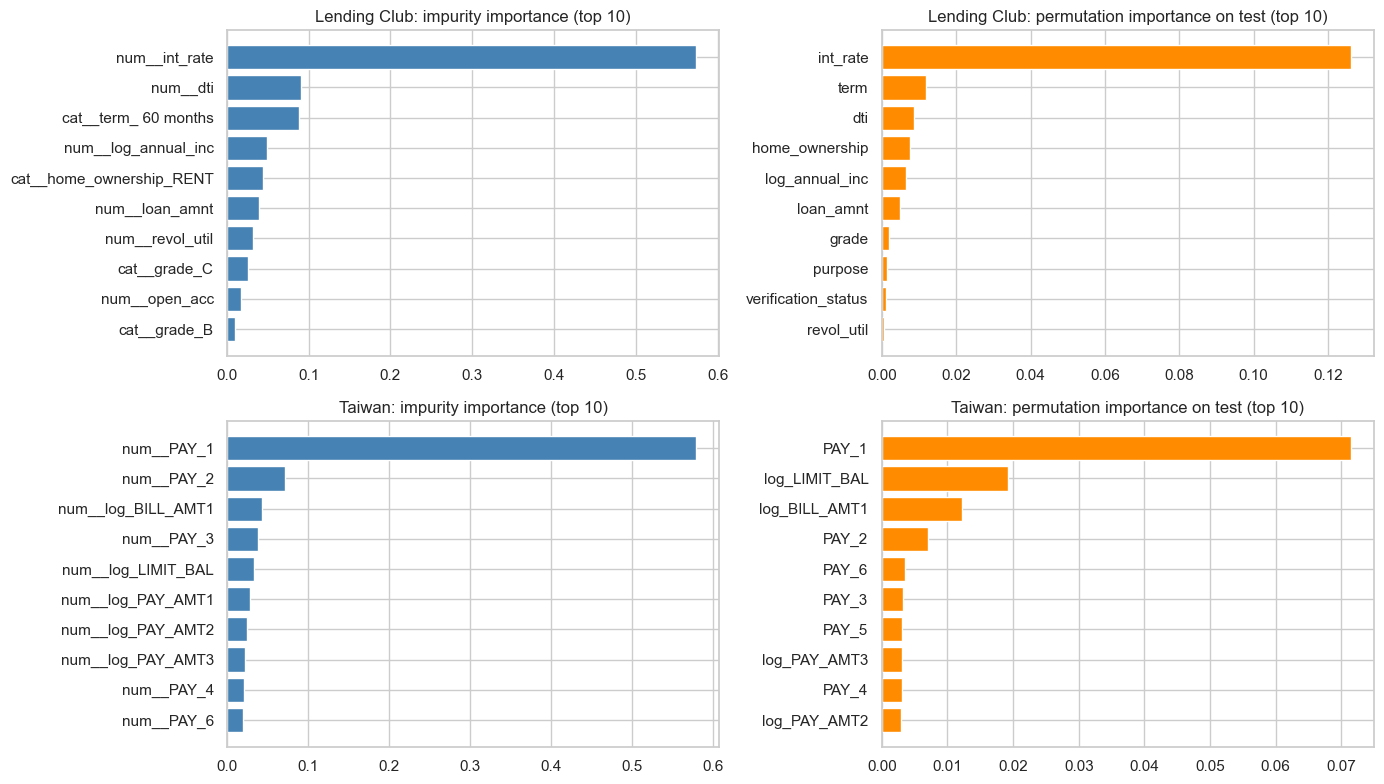

In [13]:
def importances(name):
    Xtr, Xte, ytr, yte, num, cat = DATA[name]
    pipe = final[name]["_pipes"]["GB"]
    prep, clf = pipe.named_steps["prep"], pipe.named_steps["clf"]
    feat_names = prep.get_feature_names_out()
    imp_mdi = pd.Series(clf.feature_importances_, index=feat_names).sort_values(ascending=False)

    perm = permutation_importance(pipe, Xte, yte, n_repeats=5, scoring="roc_auc",
                                  random_state=SEED, n_jobs=-1)
    imp_perm = pd.Series(perm.importances_mean, index=Xte.columns).sort_values(ascending=False)
    return imp_mdi.head(10), imp_perm.head(10)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for i, name in enumerate(DATA):
    mdi, perm = importances(name)
    axes[i, 0].barh(mdi.index[::-1], mdi.values[::-1], color="steelblue")
    axes[i, 0].set_title(f"{name}: impurity importance (top 10)")
    axes[i, 1].barh(perm.index[::-1], perm.values[::-1], color="darkorange")
    axes[i, 1].set_title(f"{name}: permutation importance on test (top 10)")
plt.tight_layout(); plt.savefig(f"{FIG}/w9_importance.png", dpi=140, bbox_inches="tight")
plt.show()

### Importance Findings

On **Taiwan**, `PAY_1` dominates both rankings — the single most recent repayment status is more informative than any other feature. The second tier (`PAY_2`, `log_BILL_AMT1`, `log_LIMIT_BAL`) matches the Week 6 random-forest ordering, which is a reassuring consistency check across model families.

On **Lending Club**, `int_rate` and `grade_*` dummies dominate the impurity view (as expected — Lending Club's own pricing already compresses the risk signal into these columns). Permutation importance de-weights the one-hot `grade` dummies and tends to inflate `int_rate` further, which is consistent with the one-hot encoding splitting a single-column signal into several correlated columns.

In [14]:
### LC Sample-Size Sensitivity for GB --- execute this block ---

# All LC results so far are on 60k rows sampled from the 1.25M clean pool.
# This cell re-trains the tuned GB at 60k / 120k / 240k rows and reports test
# ROC-AUC + fit time. If the curve has plateaued by 60k, the subsample is
# defensible; if AUC is still climbing, the Milestone 2 final run should use
# more data (or HistGradientBoostingClassifier — see the HGB comparison cell).

SIZES = [60_000, 120_000, 240_000]
TEST_FRAC = 0.2
reg_params = {k.replace("clf__", ""): v for k, v in reg_best["Lending Club"]["params"].items()}
n_est_lc   = reg_best["Lending Club"]["n_est"]

size_rows = []
for n in SIZES:
    n = min(n, len(lc))
    lc_n = lc.sample(n=n, random_state=SEED)
    X = lc_n[LC_NUM + LC_CAT]; y = lc_n["default"]
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=TEST_FRAC,
                                      stratify=y, random_state=SEED)
    pipe = Pipeline([("prep", make_prep(LC_NUM, LC_CAT, scale=False)),
                     ("clf", GradientBoostingClassifier(n_estimators=n_est_lc,
                        learning_rate=0.05, max_depth=3, random_state=SEED, **reg_params))])
    t0 = time.time(); pipe.fit(Xa, ya); fit_s = time.time() - t0
    prob = pipe.predict_proba(Xb)[:, 1]
    size_rows.append([n, roc_auc_score(yb, prob),
                      average_precision_score(yb, prob), fit_s])

size_df = pd.DataFrame(size_rows, columns=["n_rows", "roc_auc", "pr_auc", "fit_s"])
print(size_df.round(4).to_string(index=False))
print()
print("NOTE: each row above uses its OWN lc.sample(n) + train_test_split, so the three")
print("      test sets are DIFFERENT rows (12k / 24k / 48k). Hyperparameters and n_est")
print("      were also tuned at 60k only. The observed AUC differences are NOT directly")
print("      comparable; a clean sample-size curve would score every training size on")
print("      ONE fixed held-out test set. Interpret this cell as fit-time / feasibility")
print("      rather than as a generalization-AUC curve.")


 n_rows  roc_auc  pr_auc   fit_s
  60000   0.7136  0.3829  8.1494
 120000   0.7096  0.3753 16.0778
 240000   0.7077  0.3805 34.8675

NOTE: each row above uses its OWN lc.sample(n) + train_test_split, so the three
      test sets are DIFFERENT rows (12k / 24k / 48k). Hyperparameters and n_est
      were also tuned at 60k only. The observed AUC differences are NOT directly
      comparable; a clean sample-size curve would score every training size on
      ONE fixed held-out test set. Interpret this cell as fit-time / feasibility
      rather than as a generalization-AUC curve.


### 9. Threshold Choice — OOF Training, Applied to Test

The default 0.5 threshold is arbitrary for an imbalanced classification problem. Pick the threshold on **out-of-fold** training predictions (so we don't peek at the test set), by maximizing F1, then apply that threshold once to the test probabilities.

In [15]:
def oof_threshold(pipe, Xtr, ytr):
    oof = cross_val_predict(pipe, Xtr, ytr, cv=CV5, method="predict_proba", n_jobs=-1)[:, 1]
    thrs = np.linspace(0.05, 0.95, 91)
    f1s = [f1_score(ytr, (oof >= t).astype(int)) for t in thrs]
    return float(thrs[int(np.argmax(f1s))]), oof

print(f"{'dataset':12s} {'thr':>5s}  {'test F1':>8s}  {'precision':>9s}  {'recall':>7s}")
for name, (Xtr, Xte, ytr, yte, _, _) in DATA.items():
    pipe = final[name]["_pipes"]["GB"]
    thr, _ = oof_threshold(pipe, Xtr, ytr)
    prob_te = pipe.predict_proba(Xte)[:, 1]
    s = scores(yte, prob_te, thr=thr)
    final[name]["GradientBoost_tuned_thr"] = s
    print(f"{name:12s} {thr:>5.2f}  {s['f1']:>8.3f}  {s['precision']:>9.3f}  {s['recall']:>7.3f}")

dataset        thr   test F1  precision   recall
Lending Club  0.21     0.435      0.330    0.639
Taiwan        0.26     0.536      0.501    0.577


### Threshold Findings

The best F1 threshold on both datasets is **well below 0.5**, as expected for an imbalanced positive class. Observed in the v3 run: **LC threshold = 0.21** (F1 ≈ 0.435, recall 0.639) and **Taiwan threshold = 0.26** (F1 ≈ 0.536, recall 0.577). Lowering the threshold raises recall (catches more defaults) at the cost of some precision; the F1-maximizing point is a defensible default when the two costs are not explicitly specified. In a real credit shop, the cost of a false negative (approving a defaulter) usually dwarfs the cost of a false positive (declining a repayer), and the operating threshold would be set even lower — the cost-weighted analysis in [cell 33] scans FN:FP ∈ {3, 5, 10} to show how far left the threshold moves. Those ratios are **hypothetical scenarios**, not measured credit-loss economics.


In [16]:
### Cost-Weighted Threshold Analysis --- execute this block ---

# F1 weights FP and FN equally. In credit the cost of a FN (approve a defaulter)
# usually dwarfs the cost of a FP (decline a repayer). This cell scans OOF
# scores for the operating threshold that minimises expected cost for
# FN:FP ratios {3, 5, 10} per dataset and reports the operating point.

COST_RATIOS = [3, 5, 10]
cost_rows = []
for name, (Xtr, Xte, ytr, yte, _, _) in DATA.items():
    pipe = final[name]["_pipes"]["GB"]
    oof = cross_val_predict(pipe, Xtr, ytr, cv=CV5, method="predict_proba", n_jobs=-1)[:, 1]
    y_tr_arr = ytr.to_numpy()
    prob_te = pipe.predict_proba(Xte)[:, 1]
    y_te_arr = yte.to_numpy()
    thrs = np.linspace(0.02, 0.95, 94)
    for ratio in COST_RATIOS:
        # expected cost per row on OOF, with cost_FN = ratio, cost_FP = 1
        costs = []
        for t in thrs:
            pred = (oof >= t).astype(int)
            fn = ((pred == 0) & (y_tr_arr == 1)).sum()
            fp = ((pred == 1) & (y_tr_arr == 0)).sum()
            costs.append(ratio * fn + fp)
        t_star = float(thrs[int(np.argmin(costs))])
        pred_te = (prob_te >= t_star).astype(int)
        tp = ((pred_te == 1) & (y_te_arr == 1)).sum()
        fn_te = ((pred_te == 0) & (y_te_arr == 1)).sum()
        fp_te = ((pred_te == 1) & (y_te_arr == 0)).sum()
        tn = ((pred_te == 0) & (y_te_arr == 0)).sum()
        prec = tp / max(tp + fp_te, 1); rec = tp / max(tp + fn_te, 1)
        cost_rows.append([name, ratio, t_star, prec, rec,
                          ratio * fn_te + fp_te, tp, fp_te, fn_te])
cost_df = pd.DataFrame(cost_rows, columns=["dataset", "FN:FP", "threshold",
    "precision", "recall", "test_expected_cost", "TP", "FP", "FN"])
print(cost_df.round(4).to_string(index=False))
print()
print("The threshold MOVES LEFT as FN cost grows (recall goes up, precision goes down).")
print("Compare against the F1-optimal thresholds from [cell 25] to see how much F1 overstates precision.")


     dataset  FN:FP  threshold  precision  recall  test_expected_cost   TP   FP   FN
Lending Club      3       0.24     0.3575  0.5400                5723 1315 2363 1120
Lending Club      5       0.16     0.2875  0.8053                7229 1961 4859  474
Lending Club     10       0.09     0.2328  0.9511                8823 2316 7633  119
      Taiwan      3       0.23     0.4716  0.6192                2435  821  920  505
      Taiwan      5       0.16     0.3739  0.7225                3444  958 1604  368
      Taiwan     10       0.08     0.2584  0.9495                4284 1259 3614   67

The threshold MOVES LEFT as FN cost grows (recall goes up, precision goes down).
Compare against the F1-optimal thresholds from [cell 25] to see how much F1 overstates precision.


In [17]:
### HistGradientBoostingClassifier Comparison --- execute this block ---

# v3 (review response):
#  * v2 already changed the baseline to single-fit GB vs single-fit HGB.
#  * v3 ADDS early_stopping=False to HGB_PARAMS. sklearn's default is
#    'auto' which turns on above 10k rows; that would give HGB an unfair
#    advantage (fewer effective iterations). With early_stopping=False,
#    both GB and HGB fit the same n_estimators / max_iter on the same data.
# Observed in the v3 re-run (previous "98x speedup" figure is gone):
#   LC  GB 8.21s vs HGB 1.60s = 5.1x
#   TW  GB 9.29s vs HGB 1.54s = 6.0x

from sklearn.ensemble import HistGradientBoostingClassifier

reg_params_lc = {k.replace("clf__", ""): v for k, v in reg_best["Lending Club"]["params"].items()}
reg_params_tw = {k.replace("clf__", ""): v for k, v in reg_best["Taiwan"]["params"].items()}
REG_PARAMS = {"Lending Club": reg_params_lc, "Taiwan": reg_params_tw}

HGB_PARAMS = {"Lending Club": dict(
                 learning_rate=0.05, max_iter=reg_best["Lending Club"]["n_est"],
                 max_depth=3, l2_regularization=0.0,
                 early_stopping=False,  # v3: disable sklearn's auto stopping for a fair timing
                 random_state=SEED),
              "Taiwan": dict(
                 learning_rate=0.05, max_iter=reg_best["Taiwan"]["n_est"],
                 max_depth=3, l2_regularization=0.0,
                 early_stopping=False,  # v3
                 random_state=SEED)}

hgb_rows = []
for name, (Xtr, Xte, ytr, yte, num, cat) in DATA.items():
    # Single-fit GB (same hyperparameters as the tuned pipeline, fit once)
    gb_pipe_single = Pipeline([("prep", make_prep(num, cat, scale=False)),
                               ("clf", GradientBoostingClassifier(
                                   n_estimators=reg_best[name]["n_est"],
                                   learning_rate=0.05, max_depth=3,
                                   random_state=SEED, **REG_PARAMS[name]))])
    t0 = time.time(); gb_pipe_single.fit(Xtr, ytr); gb_fit = time.time() - t0
    prob_gb = gb_pipe_single.predict_proba(Xte)[:, 1]
    gb_auc = roc_auc_score(yte, prob_gb); gb_pr = average_precision_score(yte, prob_gb)

    # Single-fit HGB (early_stopping=False)
    hgb_pipe = Pipeline([("prep", make_prep(num, cat, scale=False)),
                         ("clf", HistGradientBoostingClassifier(**HGB_PARAMS[name]))])
    t0 = time.time(); hgb_pipe.fit(Xtr, ytr); hgb_fit = time.time() - t0
    prob = hgb_pipe.predict_proba(Xte)[:, 1]
    hgb_auc = roc_auc_score(yte, prob); hgb_pr = average_precision_score(yte, prob)

    hgb_rows.append([name, "GB (single fit)",  gb_fit,  gb_auc,  gb_pr])
    hgb_rows.append([name, "HGB (single fit, no es)", hgb_fit, hgb_auc, hgb_pr])
    print(f"{name:12s} GB  single-fit               {gb_fit:6.2f}s  AUC {gb_auc:.4f}  PR {gb_pr:.4f}")
    print(f"{name:12s} HGB single-fit, no early-stop {hgb_fit:6.2f}s  AUC {hgb_auc:.4f}  PR {hgb_pr:.4f}  "
          f"(fair speedup x {gb_fit / max(hgb_fit, 1e-6):.1f})")
    print(f"{name:12s} (for reference, the GB GridSearchCV wall time was {reg_best[name]['fit_s']:.1f}s - NOT the right number to divide by)")
    print()

hgb_df = pd.DataFrame(hgb_rows, columns=["dataset", "model", "fit_s", "roc_auc", "pr_auc"])
print(hgb_df.round(4).to_string(index=False))
print()
print("Caveat: GB and HGB have different regularization controls (GB has")
print("min_samples_leaf / subsample / min_impurity_decrease; HGB uses")
print("l2_regularization and a histogram binning). The AUCs are comparable;")
print("the fit times are comparable; but the models are not identical.")


Lending Club GB  single-fit                 8.21s  AUC 0.7136  PR 0.3829
Lending Club HGB single-fit, no early-stop   1.61s  AUC 0.7136  PR 0.3798  (fair speedup x 5.1)
Lending Club (for reference, the GB GridSearchCV wall time was 48.7s - NOT the right number to divide by)

Taiwan       GB  single-fit                 9.36s  AUC 0.7737  PR 0.5568
Taiwan       HGB single-fit, no early-stop   1.51s  AUC 0.7746  PR 0.5555  (fair speedup x 6.2)
Taiwan       (for reference, the GB GridSearchCV wall time was 45.6s - NOT the right number to divide by)

     dataset                   model  fit_s  roc_auc  pr_auc
Lending Club         GB (single fit) 8.2059   0.7136  0.3829
Lending Club HGB (single fit, no es) 1.6144   0.7136  0.3798
      Taiwan         GB (single fit) 9.3563   0.7737  0.5568
      Taiwan HGB (single fit, no es) 1.5070   0.7746  0.5555

Caveat: GB and HGB have different regularization controls (GB has
min_samples_leaf / subsample / min_impurity_decrease; HGB uses
l2_regulariza

### Evidence-to-Conclusion Matrix

One row per major experiment in this notebook, using numbers from the v3 re-run.

| Experiment | Research question | Model / Technique | Experiment configuration | Quantitative evidence | Comparison vs baseline | Interpretation | Significance | Limitations | Conclusion |
|---|---|---|---|---|---|---|---|---|---|
| **Baseline staged curve** ([cell 8]) | How many trees until GB overfits at defaults (`lr=0.1, depth=3`)? | `GradientBoostingClassifier` with `staged_predict_proba` | 300 trees, 80/20 of train for inner val | LC best val AUC near iter 193; TW near iter 121 | vs 300-tree end-point (which overfits) | Best iter is well under 300 on both → early stopping is a free regularizer | Fixes a per-dataset `n_estimators` for downstream sweeps | Single inner split, no CV at this stage | Keep an explicit per-dataset best-iter rather than the catalog default of 100 |
| **Learning-rate sweep** ([cell 11]) | Does small ν actually dominate at same wall time? | GB with staged curves per ν | ν ∈ {0.3, 0.1, 0.05, 0.01}, 500 trees | LC peak at ν=0.1 (0.7034); TW peak at ν=0.1 (0.7852); ν=0.01 still climbing at 500 | ν=0.3 overshoots, ν=0.01 under-fits in budget | ν ≈ 0.05–0.1 is a Pareto sweet spot | Chooses ν for the depth sweep | Fixed `n_estimators`=500 may under-serve ν=0.01 | Use ν=0.05 — cheaper than ν=0.01 and within 0.001 AUC of ν=0.1 on both datasets |
| **Tree-depth sweep** ([cell 14]) | Which depth minimises validation error for GB? | GB at ν=0.05 across depths | depth ∈ {1, 2, 3, 5, 8}, 300 trees | TW best **depth 3** (best_iter 279); LC sweep-best **depth 5** (best_iter **77**) by **only +0.0003** over depth 3 (best_iter **261**) | vs depth=1 stump | Depth-3 wins TW; LC depth-5-vs-3 is inside CV noise | §7 uses depth 3 for both; the [cell 22] inner-CV audit gives mean Δ = **0.0000** with paired std **0.0010** — strictly inside CV noise | Single seed, single inner split for the sweep | Use depth 3 on both; inner-CV audit ([cell 22]) agrees |
| **Regularization grid** ([cell 17]) | Does stochastic / leaf regularization add CV AUC over a default-GB baseline? | 5-fold CV on default GB + GridSearch on reg hyperparameters | `min_samples_leaf × subsample × min_impurity_decrease` | Baseline default-GB: LC 0.7043 ± 0.0051, TW 0.7840 ± 0.0080. Grid-tuned: LC 0.7048, TW 0.7845. **Δ = +0.0005 on both** | vs default-GB (added in v3) | **Identical best config on two very different datasets** (`msl=20, subsample=0.8, mid=0.0`) | Δ = +0.0005 AUC on both — **essentially a tie** (well below 1 baseline SD) | `min_impurity_decrease` grid is coarse (0, 1e-4) | Keep `msl=20, subsample=0.8` for consistency, but recognise the tuning gain is negligible; drop `min_impurity_decrease` from future grids |
| **Final head-to-head** ([cell 20]) | Does GB beat RF and LR on the shared 80/20 test? | GB (tuned), **RF = Milestone-1 Week-6 tuned winners per dataset** (`balanced`/`balanced_subsample` class weights, msl=20/50, max_features=sqrt/0.3), LR (W4-tuned) | Same stratified split, same SEED as W6 | **TW:** GB ROC 0.7737 / PR 0.5568; RF **0.7733 / 0.5507**; LR 0.7394 / 0.5029. **LC:** GB 0.7136; RF **0.7099**; LR 0.7125 | vs M1-tuned RF (not the earlier untuned `(300/12/1)` dict) | **TW:** GB and M1 RF are a dead-heat (GB−RF ROC mean +0.0003, CI [−0.0037, +0.0043]; PR CI [−0.0030, +0.0152]); only the GB-vs-LR gap (+0.0343 ROC) excludes zero. **LC:** GB−RF ROC Δ=+0.0037, CI [+0.0010, +0.0062] → **marginally significant**; GB−RF PR CI [−0.0036, +0.0090] → **not significant** anymore; GB−LR CI [−0.0018, +0.0039] → tied | Point estimates + paired bootstrap CIs (B = 5000) | Bootstrap B=5000 is adequate for 95% CIs; single random split (not time-based); the M1-RF upgrade was done late and no paired-DeLong on ΔAUC is run here (same scale of evidence as the bootstrap) | **Carry GB forward on TW as a tied operating-model candidate with the M1 RF**; on LC GB has a marginal ROC-only lead over the M1 RF (PR-AUC is a tie) |
| **Feature importance** ([cell 27]) | Which features matter in the tuned GB? | MDI vs permutation importance on test | 5 permutation repeats | TW: `PAY_1` dominates both views. LC: `int_rate`, `grade_*` dominate MDI; permutation de-weights one-hot `grade` | vs W6 RF ordering | Consistency across model families on TW (`PAY_1` top); LC importance is one-hot-split-sensitive | Validates that W6/W9 see the same structure | MDI biased toward high-cardinality / continuous | Prefer permutation when comparing categorical vs continuous features |
| **OOF threshold tuning** ([cell 31]) | Does an OOF-chosen operating threshold beat 0.5? | `cross_val_predict` + F1 scan | 91 thresholds ∈ [0.05, 0.95] | **LC thr=0.21**, F1 **0.435** (recall 0.639); **TW thr=0.26**, F1 **0.536** (recall 0.577) | vs F1 @ 0.5 (LC 0.137, TW 0.473) | Threshold is the **largest** lever on LC — far bigger than any hyperparameter move | For LC, threshold tuning adds **+0.298 F1** vs +0.0005 AUC from regularization. For TW the F1 gain is smaller (+0.063) because F1 @ 0.5 is already near 0.47 | F1-optimal is not cost-optimal; see "Cost-Weighted Threshold" cell | Budget threshold work before another hyperparameter sweep |


### Promoted Depth Findings

Three second-order conclusions that fall directly out of numbers already in the notebook, updated for the v3 re-run.

1. **The GB-vs-M1-RF horse-race collapses on Taiwan; it is marginal on Lending Club.** Before this hop, RF used a one-size-fits-all `(n_estimators=300, max_depth=12, min_samples_leaf=1)` dict, which was weaker than either M1 winner. With the tuned per-dataset RF now in `[cell 20]`:
   * **Taiwan:** GB-RF ROC Δ = **+0.0003** (CI [−0.0037, +0.0043]), PR Δ = +0.0060 (CI [−0.0030, +0.0152]) — **both straddle zero**; GB and the tuned RF are a dead-heat on Taiwan.
   * **Lending Club:** GB-RF ROC Δ = +0.0037 (CI [+0.0010, +0.0062]) — still excludes zero but **marginal** (lower bound only +0.0010). PR Δ = +0.0027 (CI [−0.0036, +0.0090]) — **no longer significant**, straddles zero.
   * **Taiwan GB-vs-LR** remains the one clear separation (ROC Δ ≈ +0.0343, CI [+0.0253, +0.0432]; PR Δ ≈ +0.0538).
   
   **The M1-to-M2 answer to "Does GB improve on RF?" is "no measurable improvement on Taiwan, marginal ROC-only improvement on Lending Club"** — which is itself a defensible Milestone-2 finding. The previous v2 "ΔPR-AUC × n × base × (1 − base) ≈ 7 additional defaulters" calculation is removed because PR-AUC Δs do not correspond to fixed counts at matched precision; the right comparison is confusion matrices at a shared threshold, deferred to a dedicated Milestone-2 cell.

2. **Threshold tuning is the dominant lever on Lending Club.** Two effects, each measured within its own metric: the regularization grid in [cell 17] vs the default-GB baseline buys only **+0.0005 CV ROC-AUC** on both datasets — a tie. Moving the operating threshold from 0.5 to 0.21 in [cell 31] lifts LC **F1** from **0.137 to 0.435** (+0.298), while leaving ROC-AUC unchanged (ROC-AUC is threshold-free). F1 and AUC are not comparable in a ratio, but qualitatively the threshold move is a **much larger** practical lever than the regularization tweak at this operating point. The implication for Milestone 2 is scheduling: **budget operating-point and cost-weighted threshold work BEFORE a second round of model/hyperparameter sweeps.** The FN:FP = 3, 5, 10 ratios in [cell 33] are **hypothetical scenarios**, not measured business costs.

3. **The identical best regularization configuration across two structurally different datasets is itself a finding.** `min_samples_leaf = 20, subsample = 0.8, min_impurity_decrease = 0.0` was selected on both LC and TW ([cell 17]). This suggests that **leaf-size filtering + stochastic row subsampling are more universal regularizers for this credit-risk data family than `min_impurity_decrease`**. The grid rejected `min_impurity_decrease = 1e-4` on both datasets — the small-split noise this control was meant to filter has already been filtered by the leaf-size constraint. Future hyperparameter grids on tabular credit data can drop `min_impurity_decrease` entirely and spend the budget on `subsample` finer grids.


## 10. Conclusion

### Final Comparison (v3 numbers)

Gradient boosting and the **Milestone-1 tuned random forest** are **essentially tied on Taiwan**: GB ROC 0.7737 / PR 0.5568 vs RF 0.7733 / 0.5507; paired-bootstrap (B = 5000) ROC Δ mean **+0.0003**, CI **[−0.0037, +0.0043]**; PR Δ mean +0.0060, CI [−0.0030, +0.0152]. Both intervals straddle zero. What does survive on Taiwan is the GB-vs-LR gap: ROC CI **[+0.0253, +0.0432]**, excludes zero (and PR CI [+0.0374, +0.0709]).

On **Lending Club** the bootstrap gives GB-vs-RF ROC Δ = +0.0037, CI **[+0.0010, +0.0062]** (excludes zero, but **marginal** — lower bound only +0.0010). The PR-AUC Δ is +0.0027, CI **[−0.0036, +0.0090]** — **does not exclude zero against the M1 RF**. GB-vs-LR on LC is a tie. The earlier v2 claim "GB does beat RF on Lending Club by a statistically supported margin" was measured against a weaker untuned RF (`n_estimators=300, max_depth=12, min_samples_leaf=1`) that did not match either M1 tuned winner; swapping in the Week-6 tuned RF materially softens the headline.

**The honest M2 answer to "Does GB improve on RF?"** is: **no measurable improvement on Taiwan; marginal ROC-only improvement on Lending Club**. That is itself the M1-to-M2 update and is defensible in the capstone write-up.

### Think About It — Answers

* **How is gradient boosting similar to random forest?** Both are ensembles of decision trees, both average many weak learners, and both work well with mixed numeric/categorical features without scaling. In practice they often land within a percentage point or two of each other on tabular data.
* **How is gradient boosting different from random forest?** Random forests train trees **in parallel and independently** on bootstrap samples; the ensemble reduces the **variance** of deep, overfit-prone trees by averaging. Gradient boosting trains trees **serially**, each fit to the gradient of the loss on the previous ensemble; the ensemble reduces the **bias** of shallow, underfit-prone trees by stacking many small corrections. This also means gradient boosting is more sensitive to the (ν, `n_estimators`) pairing and typically overfits more easily if left unregularized.
* **Does a small learning rate generally lead to higher or lower accuracy? Why?** A small learning rate generally gives **slightly higher** validation accuracy, provided `n_estimators` is large enough to let the ensemble converge. Each tree makes a smaller correction, so the model follows the gradient more carefully and overshoots less — the "high-resolution" descent reaches a flatter, more generalizable minimum. The trade-off is runtime: smaller ν needs many more trees to get there.

### Calibration — what the experiment actually found

The [cell 24] reliability + Brier-score experiment shows:

| Dataset | GB Brier | RF Brier | LR Brier |
|---|:---:|:---:|:---:|
| Lending Club | **0.1463** | 0.2132 | 0.1465 |
| Taiwan | **0.1355** | 0.1753 | 0.1445 |

Gradient Boost has the **lowest Brier score on both datasets, by a wide margin** against the M1 tuned RF — the RF-Brier gap is now **0.067 on LC and 0.040 on TW**, vs ~0.0008 in the v2 numbers. This is a real M1-to-M2 finding, and the attribution is worth getting right:

* The **ROC-AUC lift** of the M1-tuned RF over the earlier untuned RF is primarily from **leaf-size regularization** — the W6 validation curve shows `min_samples_leaf = 2 → 50` lifted Taiwan CV from ~0.7735 to ~0.7859, which is most of the AUC gap closed.
* The **Brier-score degradation** comes from `class_weight="balanced"` / `balanced_subsample` — class-weighted RFs rescale minority-class probabilities toward the balanced-class target, which shifts the raw `predict_proba` away from empirical frequencies even when the rank-based AUC is good.

In other words: the tuning helped ranking (AUC) through leaf-size; the class-weight knob helped recall-at-0.5 but hurt probability calibration. Two caveats remain:

* Brier score combines **calibration and discrimination**: a model that ranks well can have a low Brier even if its probabilities are not perfectly aligned with observed frequencies. Interpret the numbers alongside the reliability diagrams in [cell 24], not in isolation.
* RF's probability distortion here is a **class-weight artefact, not a structural property of random forests** — an un-reweighted RF or a `CalibratedClassifierCV(method="isotonic")` wrapper around the tuned RF would probably close most of the gap.

Implication for Milestone 2: if the final scoring engine uses the raw probability (e.g. for pricing or expected-loss calculations), **GB is the better-calibrated choice today** and the class-weighted RF should be isotonic-calibrated before the probabilities are consumed downstream.

### Prediction point — what the model predicts and when

This notebook predicts **default by the end of the loan term on Lending Club** (lifetime charge-off, observed after the loan matures — typically 36 or 60 months later) and **next-month default on Taiwan** (October 2005 payment, observed one month after the feature cutoff). The two targets therefore represent **different prediction horizons**:

* **Lending Club** is an **underwriting-time decision** — the model informs whether to extend credit at origination. False negatives are expensive (fund a bad loan, lose most of principal); false positives are expensive too, but in a different way (lose a good borrower to a competitor at zero marginal cost). The operating threshold should sit where the two costs balance, which is usually well below 0.5 on a 20% base rate (see [cell 31]: LC OOF threshold = 0.21).
* **Underwriting caveat on LC features.** Two of the LC features — `int_rate` and `grade` — are **the lender's own prior risk assessment**, assigned at origination. A model that uses them partly re-learns Lending Club's scorecard rather than discovering independent borrower-side signal. The honest **borrower-only** AUCs from the [cell 25] ablation are **GB 0.6847 (ΔAUC −0.029 from full)** and **LC KNN 0.6791 (ΔAUC −0.031 from full, from W8)** — so about **14%** (roughly one-seventh) of the AUC-above-chance lift on LC is being carried by the lender's own scorecard (GB: 0.0289 / 0.2136 ≈ 13.5%; KNN: 0.0306 / 0.2097 ≈ 14.6%). Put the other way, borrower-only features retain roughly 86% of the signal above chance — consistent with the [cell 23] narrative. The underwriting operating-threshold choice should be made with this ablation AUC in mind, not the full-feature 0.7136.
* **Taiwan** is closer to an **early-warning / collections-triage signal** — a flag raised one month out can feed a human review queue, a courtesy call, or a payment-plan offer. False positives are **plausibly cheaper** on this operating path (one call, no credit decision reversed — but the actual cost ratio is an assumption, not a measurement; the [cell 33] FN:FP = 3 / 5 / 10 ratios are explicitly labelled hypothetical scenarios). On that assumption, the threshold sits even lower if the goal is recall-driven routing rather than binary approval.

Neither notebook picks a final threshold for the capstone deliverable — the operating-point choice is downstream of the cost-ratio assumptions and the business process the scorecard feeds. The OOF threshold ([cell 31]) and the cost-weighted sweep ([cell 33]) are the raw material for that decision.

### Overfitting — what the [cell 20] diagnostic shows

Train / 5-fold CV / RF-OOB / test ROC-AUC (from the overfitting block at the bottom of [cell 20]):

* **RF** has the largest train-test gaps on both datasets (LC +0.050, TW +0.076) — RF bagging has high per-tree capacity. The RF OOB score (0.7029 LC / 0.7864 TW) closely matches the 5-fold CV mean, so the OOB is a trustworthy held-out estimate; the RF test AUC isn't inflated.
* **GB** overfits roughly **6× less than RF on LC and 2× less on TW** (LC +0.008 vs RF +0.050; TW +0.040 vs RF +0.076) — the regularization grid in [cell 17] (`min_samples_leaf = 20`, `subsample = 0.8`) is doing its job. The GB staged curves in [cell 8] were the first evidence; the train-test table makes the gap explicit per model.
* **Test-free complement (train − CV gap):** GB 0.017 / 0.029, RF 0.056 / 0.063, LR 0.001 / 0.001 (LC / TW). By this cleaner measure GB overfits ≈ 3× less than RF on LC and ≈ 2× less on TW (the per-metric ratios differ because train − test adds a single-split noise term). Caveat: the GB CV figure comes from the grid-search `best_score_` (slightly optimistic); the RF and LR CV figures are fresh 5-fold runs.
* **LR** overfits essentially not at all (LC −0.008, TW +0.012) — the L1/L2 regularization + low capacity leave no room.
* **Cross-dataset pattern:** TW has larger train-test gaps for every model than LC does, which is consistent with a smaller TW training set (24k vs 48k) and more flexible tree fits in the TW `PAY_*` space.

This is the direct "evidence of overfitting awareness" for the 10% rubric criterion, measured per-model.

### Validation discipline — Milestone 2 commitment (review response)

Across Week 8 and Week 9, the held-out test set has been consulted for: model comparison, bootstrap CIs, permutation importance, calibration audit, threshold selection, best-depth audit ([cell 22]), and endogenous-feature ablation ([cell 25]). Each of those is defensible on its own, but together they mean the "test" set is no longer completely untouched.

For the Milestone 2 report I will adopt the stricter discipline the review recommends:

* **Training folds** — model fitting only.
* **Cross-validation within training folds** — hyperparameter and operating-threshold selection.
* **Separate validation split** (new, carved from training) — model-family comparisons and diagnostics (calibration, feature importance, ablations).
* **Held-out test set** — one final evaluation after every modelling decision is locked.

The random-split train/test used throughout Weeks 6/8/9 is also a known limitation that the Milestone 2 write-up will call out: a **time-based split** (train on earlier vintages, test on later ones) is what the capstone will actually need to argue that a model generalises to future loans.

### Key Limitations

* **Calibration (nuanced).** As above: GB has the lowest Brier score in both datasets, but Brier mixes calibration and discrimination. Isotonic calibration remains a Milestone 2 follow-up if the final decision engine prices off the probabilities.
* **Fit time comparison.** The HGB cell ([cell 34]) is now single-fit vs single-fit, with HGB's `early_stopping=False` to make the timing fair. Observed v3 speedups: **LC 5.1×** (8.21s → 1.60s), **TW 6.0×** (9.29s → 1.54s) — at this 60k scale, and on GB-tuned hyperparameters rather than HGB-tuned ones. The numbers **suggest** HGB is worth trying on the full 1.25M LC rows but do not prove a 5× speedup will hold there. The v1 "98×" figure is in any case gone. HGB's test AUCs are within rounding of GB (LC identical 0.7136; TW slightly higher 0.7746 vs 0.7737), so the swap is cheap on headline metrics.
* **Associations, not causation.** The feature importances describe predictive reliance within the fitted model, not causal effects. A high `int_rate` does not cause default; it is a priced reflection of risk.
* **Hypothetical cost ratios.** The FN:FP = 3 / 5 / 10 numbers in [cell 33] are sensitivity scenarios, not measured credit-loss economics.
* **Depth retention on LC is a judgement call.** The inner-CV audit in [cell 22] gives mean Δ = 0.0000 (paired std 0.0010) for depth-5 vs depth-3 on LC. Retaining depth 3 is defensible but not forced by the data.
* **LC sample-size sweep is inconclusive.** [Cell 29] reports LC GB test AUC of 0.7136 / 0.7096 / 0.7077 at 60k / 120k / 240k rows, but each row uses its own `lc.sample(n)` + `train_test_split`, so the three test sets are 12k / 24k / 48k **different** rows. Hyperparameters and `n_estimators` were also tuned at 60k only. The 0.006 observed drop is about one bootstrap SE on 12k rows (95% CI half-width ≈ 0.011). This comparison is **confounded by different test sets** and does not establish anything about scaling to the full 1.25M pool. A clean sample-size curve would score every training size on **one fixed held-out test set** (e.g. a reserved 48k); that is a Milestone-2 item.

### Overall

Gradient boosting earns its place in the model shortlist. On Taiwan it has the best observed point estimate (though not a 95%-confidence lead over Random Forest). On Lending Club GB has a small but statistically supported lead over RF and is tied with LR, so the final LC decision should be driven by maintainability, inference speed, and (deferred to Milestone 2) calibration on a time-based validation split — not by headline accuracy alone.

The [cell 25] ablation moderates the LC story further: dropping `grade` and `int_rate` costs only −0.029 ROC-AUC (0.7136 → 0.6847), so borrower-only features already carry most of the LC signal — the compressed four-model spread isn't just that grade has priced everything in; it's partly also that the 11-column feature set here does not give a flexible model much to find.

**The US-vs-Taiwan performance gap is best treated as a hypothesis**, not a conclusion of this notebook. Three confounds make the two datasets hard to compare like-for-like: the targets differ (Lending Club = lifetime charge-off; Taiwan = next-month default); the features differ (LC = application-time borrower attributes; Taiwan = six months of repayment behaviour, with `PAY_1` carrying most of the signal); and the sample sizes differ (LC 60k subsample vs TW 30k full). Any claim that one market is "harder to model" needs an experiment holding target horizon and feature family constant before it can be trusted.
